# Projet final : deviner le genre d'une chanson à partir de ses paroles

## L'idée du projet
On donne au modèle les **paroles** d'une chanson, et il doit deviner son **genre musical** : Rock, Pop, Metal, Jazz…

Tout le projet est dans ce notebook. On commence par les données et les modèles. On garde le meilleur modèle, puis on construit une petite application web avec Streamlit, pour que n'importe qui puisse l'utiliser depuis son navigateur.

## Ce qu'on fait, étape par étape
| Partie | Ce qu'on fait |
|---|---|
| 1. Le dataset | on charge les données et on explique pourquoi on les a choisies |
| 2. Exploration | on regarde les données de près : genres, langues, longueur des textes, pièges |
| 3. Prétraitement | on nettoie les textes, on regroupe les genres trop rares, on sépare train / validation / test |
| 4. Machine Learning | Naive Bayes, SVM, régression logistique, KNN |
| 5. Deep Learning | MLP, RNN, LSTM, Transformer |
| 6. Comparaison | on met tous les modèles côte à côte |
| 7. Choix du modèle | on choisit le meilleur et on le teste sur des données jamais vues |
| 8. Sauvegarde | on enregistre le modèle pour l'application |
| 9. L'application | on écrit l'application Streamlit, on la teste, puis on la lance sur l'ordinateur |
| 10. La mise en ligne | on exporte le modèle pour une page web (GitHub Pages) et on explique comment tout publier sur internet |

**Attention :** l'exécution complète prend environ une heure sur un ordinateur sans carte graphique, surtout à cause des réseaux de neurones (partie 5).

## Imports
On importe toutes les librairies dont on aura besoin.

In [1]:
import json
import time
import platform
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn

from datasets import load_dataset

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedGroupKFold
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.preprocessing import LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import MultinomialNB, ComplementNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    classification_report, confusion_matrix
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import keras_hub

warnings.filterwarnings("ignore")
keras.utils.set_random_seed(42)

c:\anaconda\Lib\site-packages\pandas\core\computation\expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


## 1. Le dataset

On utilise le dataset **`perceptron-743/music-multi-lingual`**, disponible sur Hugging Face. Chaque ligne est une chanson, avec :

- `Artist` et `Song` : l'artiste et le titre ;
- `Lyrics` : les **paroles**. C'est ce qu'on donne au modèle (la variable explicative) ;
- `Genre` : le **genre**. C'est ce que le modèle doit deviner (la variable à prédire) ;
- `Language` : la langue des paroles ;
- `Song year` et `Track_id` : l'année et un identifiant.

**Pourquoi ce dataset ?**
- C'est de la **classification de texte**, comme dans les TP (20 newsgroups, IMDB, AG News).
- C'est **plus difficile** qu'AG News. Pour un article de presse, le texte suffit à trouver le thème. Pour une chanson, le genre dépend aussi de la musique, et pas seulement des paroles.
- Il y a beaucoup plus de chansons dans certains genres que dans d'autres, et plusieurs langues. Ça nous oblige à réfléchir à nos choix.

Le dataset est déjà coupé en `train`, `val` et `test`. Comme dans les TP, on **recolle les trois morceaux** pour refaire notre propre découpage. On explique pourquoi dans la partie 3.

In [2]:
dataset = load_dataset("perceptron-743/music-multi-lingual")
print(dataset)

df = pd.concat(
    [dataset["train"].to_pandas(), dataset["val"].to_pandas(), dataset["test"].to_pandas()],
    ignore_index=True
)

print("\nDimensions :", df.shape)
display(df.head())

DatasetDict({
    train: Dataset({
        features: ['Artist', 'Song', 'Genre', 'Language', 'Lyrics', 'Song year', 'Track_id'],
        num_rows: 50000
    })
    test: Dataset({
        features: ['Artist', 'Song', 'Genre', 'Language', 'Lyrics', 'Song year', 'Track_id'],
        num_rows: 5000
    })
    val: Dataset({
        features: ['Artist', 'Song', 'Genre', 'Language', 'Lyrics', 'Song year', 'Track_id'],
        num_rows: 5000
    })
})

Dimensions : (60000, 7)


,Artist,Song,Genre,Language,Lyrics,Song year,Track_id
0,glenn frey,let's pretend we're still in love,Rock,en,"Hello, baby, how've you been You sure are loo...",None,None
1,glee,have yourself a merry little christmas,Pop,en,Have yourself a merry little Christmas Let you...,None,None
2,dolly parton,put it off until tomorrow,Pop,en,Put it off until tomorrow Wo-wo You've hurt...,None,None
3,brian mcknight,kiss your love goodbye,R&B,en,"Tell, tell me it isn't so You say you have you...",None,None
4,becky g,novacane,Pop,en,Yo yo Yo yo Here to make a mixtape I'll do it ...,None,None


## 2. Exploration des données

### 2.1 Valeurs manquantes et doublons

In [3]:
df.info()

print("\nValeurs manquantes par colonne :")
print(df.isna().sum())

print("\nDoublons dans les paroles :", df["Lyrics"].duplicated().sum())
print("Nombre d'artistes :", df["Artist"].nunique())

<class 'pandas.DataFrame'>
RangeIndex: 60000 entries, 0 to 59999
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Artist     60000 non-null  str   
 1   Song       60000 non-null  str   
 2   Genre      60000 non-null  str   
 3   Language   60000 non-null  str   
 4   Lyrics     60000 non-null  str   
 5   Song year  0 non-null      object
 6   Track_id   0 non-null      object
dtypes: object(2), str(5)
memory usage: 73.3+ MB

Valeurs manquantes par colonne :
Artist           0
Song             0
Genre            0
Language         0
Lyrics           0
Song year    60000
Track_id     60000
dtype: int64

Doublons dans les paroles : 2983
Nombre d'artistes : 6746


- Les colonnes `Song year` et `Track_id` sont **complètement vides**, donc on les supprimera.
- Les autres colonnes sont complètes.
- Environ **3 000 paroles apparaissent deux fois** (une chanson en version live, en remaster…). On enlèvera les doublons. Sinon, la même chanson pourrait se retrouver à la fois dans les données d'entraînement et dans celles de test : le modèle serait testé sur une chanson qu'il connaît déjà.

### 2.2 Combien de chansons par genre ?

            Nombre  Pourcentage
Genre                          
Rock         25599        42.66
Pop          21820        36.37
Metal         4205         7.01
Jazz          2931         4.88
Folk          1792         2.99
Indie         1733         2.89
R&B            579         0.97
Hip-Hop        505         0.84
Electronic     448         0.75
Country        388         0.65


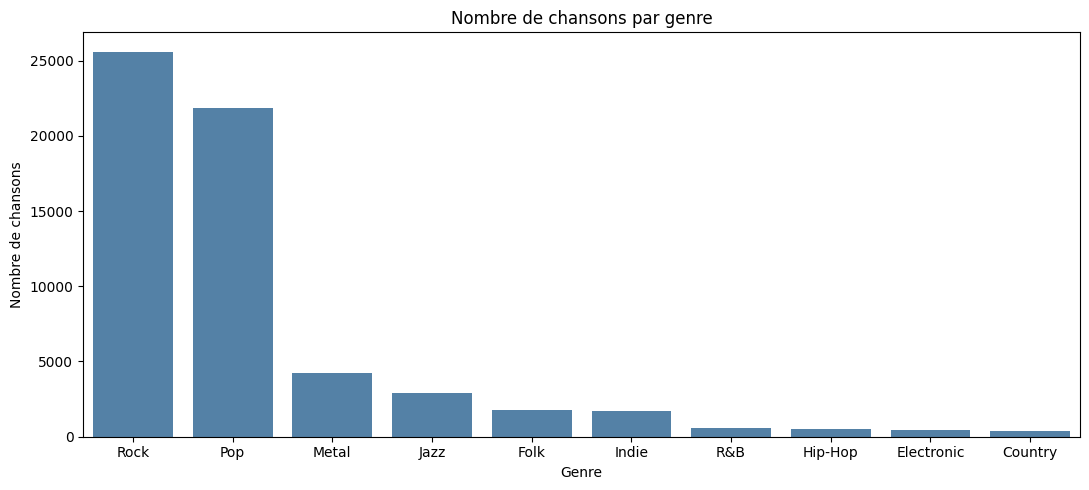

In [4]:
class_counts = df["Genre"].value_counts()

print(pd.DataFrame({
    "Nombre": class_counts,
    "Pourcentage": (df["Genre"].value_counts(normalize=True) * 100).round(2)
}))

plt.figure(figsize=(11, 5))
sns.barplot(x=class_counts.index, y=class_counts.values, color="steelblue")
plt.title("Nombre de chansons par genre")
plt.xlabel("Genre")
plt.ylabel("Nombre de chansons")
plt.tight_layout()
plt.show()

**Les genres sont très déséquilibrés.** Rock et Pop représentent à eux deux environ **79 %** des chansons. À l'inverse, R&B, Hip-Hop, Electronic et Country ont chacun **moins de 1 %** des chansons, soit quelques centaines seulement.

Ce que ça change pour la suite :
1. **L'accuracy ne suffit pas.** Un modèle qui répondrait « Rock » à chaque fois aurait déjà environ 43 % de bonnes réponses, sans rien avoir appris. On va donc surtout regarder le **F1 macro**. Il calcule un score pour chaque genre, puis fait la moyenne : un genre rare compte autant qu'un genre fréquent.
2. Il faudra **aider le modèle avec les genres rares**, avec par exemple `class_weight="balanced"`.
3. Les 4 genres les plus rares seront **regroupés dans une classe « Autres »** (partie 3.2).
4. Quand on sépare les données, il faudra garder les mêmes proportions de genres partout (`stratify`).

### 2.3 Dans quelles langues sont les paroles ?

Language
en    53307
pt     6329
ro      250
de      114
Name: count, dtype: int64


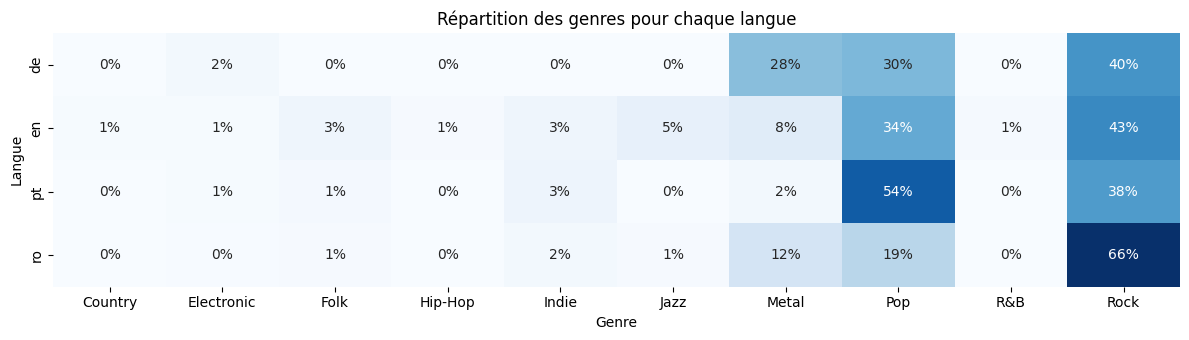

In [5]:
print(df["Language"].value_counts())

plt.figure(figsize=(12, 3.5))
sns.heatmap(pd.crosstab(df["Language"], df["Genre"], normalize="index"),
            annot=True, fmt=".0%", cmap="Blues", cbar=False)
plt.title("Répartition des genres pour chaque langue")
plt.xlabel("Genre")
plt.ylabel("Langue")
plt.tight_layout()
plt.show()

- La grande majorité des chansons sont **en anglais** (environ 89 %). Environ 10 % sont en **portugais**, et il y a un peu de roumain et d'allemand.
- Les chansons en portugais sont presque toutes classées Pop ou Rock.
- **Ce que ça change :** on n'utilisera pas la liste de « stop words » anglais de scikit-learn (les mots trop courants comme *the*, *and*…), car elle ne marcherait que pour l'anglais. À la place, on supprimera les mots trop fréquents avec le paramètre `max_df` du TF-IDF, qui marche quelle que soit la langue.

### 2.4 Longueur des paroles

count    60000.0
mean       237.4
std        145.9
min          1.0
25%        142.0
50%        204.0
75%        289.0
max       2200.0
Name: word_count, dtype: float64

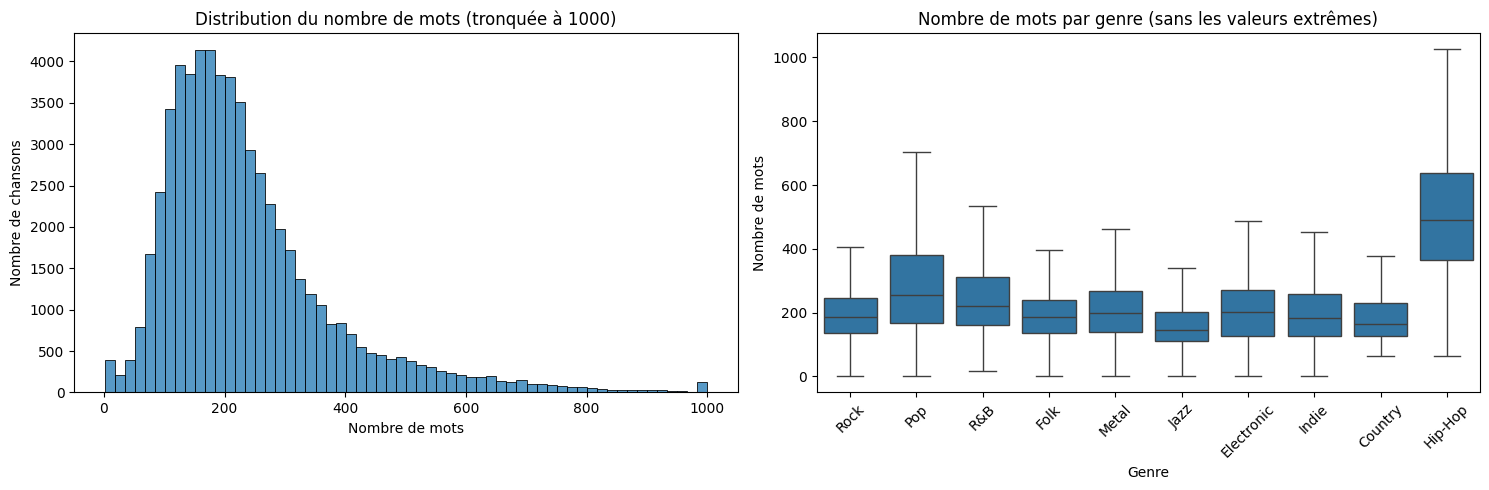

Genre
Jazz          144.0
Country       163.5
Indie         184.0
Folk          185.0
Rock          187.0
Metal         198.0
Electronic    203.0
R&B           222.0
Pop           254.0
Hip-Hop       490.0
Name: word_count, dtype: float64


In [6]:
df["word_count"] = df["Lyrics"].apply(lambda x: len(x.split()))

display(df["word_count"].describe().round(1))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(df["word_count"].clip(upper=1000), bins=60, ax=axes[0])
axes[0].set_title("Distribution du nombre de mots (tronquée à 1000)")
axes[0].set_xlabel("Nombre de mots")
axes[0].set_ylabel("Nombre de chansons")

sns.boxplot(data=df, x="Genre", y="word_count", showfliers=False, ax=axes[1])
axes[1].set_title("Nombre de mots par genre (sans les valeurs extrêmes)")
axes[1].set_xlabel("Genre")
axes[1].set_ylabel("Nombre de mots")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

print(df.groupby("Genre")["word_count"].median().sort_values())

- Une chanson fait en moyenne environ **240 mots**. La plupart sont assez courtes, mais quelques-unes dépassent 2 000 mots.
- **Le Hip-Hop sort du lot** : environ 490 mots en médiane, deux fois plus que les autres genres. C'est logique, le rap contient beaucoup de texte. À l'inverse, le Jazz a les textes les plus courts.
- Pour les réseaux de neurones, tous les textes doivent avoir la même longueur. On choisira **300 mots** : c'est assez pour garder en entier environ 3 chansons sur 4, et le début des autres.

### 2.5 Les textes très courts

In [7]:
short_texts = df[df["word_count"] < 20]
print("Chansons de moins de 20 mots :", len(short_texts))
print(short_texts["Lyrics"].str.lower().str.strip().value_counts().head(10))

Chansons de moins de 20 mots : 409
Lyrics
instrumental                                                                                               177
[instrumental]                                                                                              35
(instrumental)                                                                                              27
[this song is an instrumental.].                                                                             4
introdução                                                                                                   3
isntrumental                                                                                                 3
instrumental - álbum: (2010) lp underground x demos                                                          3
instrumental.                                                                                                2
lighten up shine like the sun.                                        

La plupart des textes de moins de 20 mots contiennent juste le mot « *Instrumental* » : ce sont des morceaux sans paroles. Ils ne disent rien sur le genre, donc on les enlèvera.

### 2.6 Le lien entre l'artiste et le genre

In [8]:
genres_per_artist = df.groupby("Artist")["Genre"].nunique()
print("Nombre de genres différents par artiste :")
print(genres_per_artist.value_counts())

print("\nNombre moyen de chansons par artiste :", round(df["Artist"].value_counts().mean(), 1))

print("\nNombre d'artistes par genre :")
print(df.groupby("Genre")["Artist"].nunique().sort_values())

Nombre de genres différents par artiste :
Genre
1    6485
2     261
Name: count, dtype: int64

Nombre moyen de chansons par artiste : 8.9

Nombre d'artistes par genre :
Genre
Country        128
R&B            152
Electronic     213
Hip-Hop        228
Folk           301
Indie          458
Jazz           623
Metal          638
Pop           2010
Rock          2256
Name: Artist, dtype: int64


**C'est un point important.** Environ **96 % des artistes n'ont qu'un seul genre**, et chaque artiste a en moyenne 9 chansons dans le dataset.

Imaginons qu'on sépare les données au hasard avec `train_test_split`. Les chansons d'un même artiste se retrouveraient à la fois dans le train et dans le test. Le modèle pourrait alors apprendre à **reconnaître l'artiste** (son style, les mots qu'il utilise souvent, son nom cité dans les paroles…) plutôt que le **genre**. Ses résultats sur le test paraîtraient meilleurs qu'ils ne le sont vraiment.

Or, dans l'application, les gens taperont des chansons d'artistes que le modèle n'a jamais vus. Pour que le test ressemble à cette situation, on va **séparer les données par artiste** : toutes les chansons d'un artiste iront soit dans le train, soit dans la validation, soit dans le test, jamais dans deux à la fois.

On voit aussi que les genres rares ont **très peu d'artistes** (128 pour Country, 152 pour R&B). Le modèle aurait trop peu d'exemples variés pour bien les reconnaître. C'est une raison de plus pour les regrouper.

### 2.7 Les étiquettes sont-elles fiables ?
On a l'impression que le genre est donné **à l'artiste**, et pas à chaque chanson. Pour le vérifier, on cherche les chansons qui contiennent des mots typiques du rap, et on regarde dans quel genre elles sont classées.

In [9]:
rap = df["Lyrics"].str.lower().str.contains(r"\b(?:nigga|niggas|bitch)\b")

print("Chansons avec du vocabulaire de rap, par genre :")
print(df[rap]["Genre"].value_counts())

print("\nArtistes classés 'Pop' qui utilisent le plus ce vocabulaire :")
print(df[rap & (df["Genre"] == "Pop")]["Artist"].value_counts().head(10))

Chansons avec du vocabulaire de rap, par genre :
Genre
Pop           2554
Hip-Hop        270
Rock           162
Metal           94
Indie           36
Jazz            33
R&B             17
Folk            10
Electronic       6
Country          1
Name: count, dtype: int64

Artistes classés 'Pop' qui utilisent le plus ce vocabulaire :
Artist
lil wayne      98
50 cent        98
nicki minaj    91
snoop dogg     72
chris brown    68
fat joe        55
jay z          54
wiz khalifa    47
t i            43
meek mill      41
Name: count, dtype: int64


**Une partie des étiquettes est fausse.** Des rappeurs très connus comme Lil Wayne, 50 Cent, Snoop Dogg, Jay-Z ou Nicki Minaj sont classés **Pop** dans ce dataset. Résultat : il y a environ **10 fois plus** de chansons de rap classées Pop que classées Hip-Hop.

Le modèle va donc apprendre que les mots du rap correspondent plutôt à de la Pop. Ce n'est pas la faute du modèle, c'est **une limite des données**. On garde quand même les étiquettes telles quelles, car les corriger à la main prendrait beaucoup de temps et sortirait du cadre du projet. Mais il faudra s'en souvenir en lisant les résultats.

### 2.8 À quoi ressemblent les paroles ?

In [10]:
for genre in ["Rock", "Hip-Hop", "Jazz", "Metal"]:
    exemple = df[df["Genre"] == genre].iloc[0]
    print(f"--- {genre} : {exemple['Artist']} - {exemple['Song']}")
    print(exemple["Lyrics"][:400], "...\n")

print("Paroles avec des balises [Chorus], [Verse]... :", round(df["Lyrics"].str.contains(r"\[.*?\]").mean() * 100, 1), "%")

--- Rock : glenn frey - let's pretend we're still in love
Hello, baby, how've you been  You sure are looking fine  I just had to look you up  'Cause, you've been on my mind   It's been awhile, we've been apart  I've finally had a chance to search my heart  It doesn't seem to matter what I do  I still keep thinkin' about me and you   Let's pretend we're still in love  And the stars above, are shining for you and me  Let's pretend our love is kissed, on a  ...

--- Hip-Hop : asian dub foundation - tu meri
Tu meri me tera You are mine And I am yours Standing together side by side I'm not your shadow but I could be your guide Stick with me in this time of insanity Working together to survive this reality Without you I don't think I could bear Belief in myself man you take me there You see me as I am and what I wanna be The hopes for myself yes you are the key And when I'm on the mic I don't have to c ...

--- Jazz : bill charlap - always
The moment I saw him smile I knew he was just my sty

Les paroles sont brutes : il y a des majuscules, de la ponctuation, et environ 10 % des chansons contiennent des indications comme `[Chorus]` ou `[Verse 1]`. Ces indications n'ont rien à voir avec le genre. On trouve aussi parfois le pseudo de la personne qui a recopié les paroles (`@pseudo`), ou des adresses de sites. On va nettoyer tout ça dans la partie suivante.

## 3. Prétraitement

### 3.1 La fonction de nettoyage

On écrit la fonction de nettoyage dans un **fichier à part**, `pretraitement.py`, grâce à `%%writefile`.

**Pourquoi un fichier à part ?** Le modèle qu'on va sauvegarder utilise cette fonction. Quand l'application rechargera le modèle, elle aura besoin de la retrouver, et elle ne peut la retrouver que dans un fichier `.py`. Avantage : un texte tapé dans l'application sera nettoyé **exactement comme** les textes d'entraînement.

La fonction met tout en minuscules, puis enlève les indications `[Chorus]`, les répétitions `(x3)`, les adresses web, les pseudos, la ponctuation et les chiffres. On garde les lettres accentuées, pour le portugais.

In [11]:
%%writefile pretraitement.py
import re


def nettoyer_texte(texte):
    """Nettoie des paroles : minuscules, sans balises, URL, pseudos, chiffres ni ponctuation."""
    texte = str(texte).lower()
    texte = texte.replace("’", "'")
    texte = re.sub(r"\[.*?\]", " ", texte)               # balises [Chorus], [Verse 1]...
    texte = re.sub(r"\(x\d+\)|\bx\d+\b", " ", texte)    # répétitions (x3), x2
    texte = re.sub(r"http\S+|www\.\S+", " ", texte)      # URL
    texte = re.sub(r"@\w+", " ", texte)                  # pseudos @...
    texte = re.sub(r"[^\w\s']", " ", texte)              # ponctuation (on garde les lettres accentuées)
    texte = re.sub(r"[\d_]", " ", texte)                 # chiffres
    texte = re.sub(r"\s'|'\s", " ", texte)               # apostrophes seules
    texte = re.sub(r"\s+", " ", texte)                   # espaces multiples
    return texte.strip()

Overwriting pretraitement.py


In [12]:
from pretraitement import nettoyer_texte

exemple = "[Chorus] Let's pretend we're STILL in love!! (x3)\nwww.lyrics.com @carol 2004 Ação"
print("Avant :", exemple)
print("Après :", nettoyer_texte(exemple))

Avant : [Chorus] Let's pretend we're STILL in love!! (x3)
www.lyrics.com @carol 2004 Ação
Après : let's pretend we're still in love ação


### 3.2 Nettoyage des données et regroupement des genres rares
On applique ce qu'on a remarqué pendant l'exploration :
1. on supprime les deux colonnes vides ;
2. on nettoie les paroles ;
3. on enlève les doublons ;
4. on enlève les textes de moins de 20 mots ;
5. on **regroupe R&B, Hip-Hop, Electronic et Country dans une seule classe « Autres »**.

**Pourquoi regrouper ces 4 genres ?** Chacun a moins de 1 % des chansons, et peu d'artistes. Le modèle n'arriverait presque jamais à les reconnaître séparément, et ils feraient baisser le score sans rien apporter. Ensemble, ils forment une classe d'environ 1 900 chansons. On passe ainsi de 10 genres à **7 classes**.

In [13]:
print("Nombre de chansons au départ :", len(df))

df = df.drop(columns=["Song year", "Track_id"])

df["text_clean"] = df["Lyrics"].apply(nettoyer_texte)
df["word_count"] = df["text_clean"].apply(lambda x: len(x.split()))

df = df.drop_duplicates(subset="text_clean")
print("Après suppression des doublons :", len(df))

df = df[df["word_count"] >= 20].reset_index(drop=True)
print("Après suppression des textes courts :", len(df))

# Regroupement des genres rares
genres_rares = ["R&B", "Hip-Hop", "Electronic", "Country"]
df["Genre"] = df["Genre"].replace(genres_rares, "Autres")

print("\nRépartition des genres après regroupement :")
print(df["Genre"].value_counts())

Nombre de chansons au départ : 60000
Après suppression des doublons : 56418
Après suppression des textes courts : 56261

Répartition des genres après regroupement :
Genre
Rock      24327
Pop       20601
Metal      4050
Jazz       2028
Autres     1872
Folk       1723
Indie      1660
Name: count, dtype: int64


### 3.3 Séparation en train, validation et test

On coupe les données en trois, environ **70 % / 15 % / 15 %**, comme dans le TP sur les réseaux de neurones :
- le **train** sert à entraîner les modèles et à régler leurs paramètres ;
- la **validation** sert à comparer tous les modèles entre eux, ceux de Machine Learning comme ceux de Deep Learning ;
- le **test** sert une seule fois, tout à la fin, pour mesurer le score du modèle choisi.

Au lieu de `train_test_split`, on utilise `StratifiedGroupKFold`, qui fait deux choses à la fois :
- il garde à peu près les mêmes proportions de genres dans chaque morceau (comme `stratify=y`) ;
- il met toutes les chansons d'un même artiste dans le même morceau (le « group »).

`StratifiedGroupKFold` découpe les données en plusieurs parts. Avec 7 parts, une part fait environ 15 % : on en prend une pour le test. Puis on refait la même chose sur ce qui reste pour obtenir la validation.

In [14]:
cv = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=42)
train_index, test_index = next(cv.split(df, df["Genre"], groups=df["Artist"]))
df_temp = df.iloc[train_index]
df_test = df.iloc[test_index]

cv = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=42)
train_index, val_index = next(cv.split(df_temp, df_temp["Genre"], groups=df_temp["Artist"]))
df_train = df_temp.iloc[train_index]
df_val = df_temp.iloc[val_index]

print("Train      :", len(df_train))
print("Validation :", len(df_val))
print("Test       :", len(df_test))

# Vérification : aucun artiste en commun entre les ensembles
print("\nArtistes communs train / val  :", len(set(df_train["Artist"]) & set(df_val["Artist"])))
print("Artistes communs train / test :", len(set(df_train["Artist"]) & set(df_test["Artist"])))
print("Artistes communs val / test   :", len(set(df_val["Artist"]) & set(df_test["Artist"])))

print("\nProportions des genres (%) :")
display(pd.DataFrame({
    "Train": df_train["Genre"].value_counts(normalize=True),
    "Validation": df_val["Genre"].value_counts(normalize=True),
    "Test": df_test["Genre"].value_counts(normalize=True),
}).mul(100).round(1))

Train      : 40186
Validation : 8038
Test       : 8037

Artistes communs train / val  : 0
Artistes communs train / test : 0
Artistes communs val / test   : 0

Proportions des genres (%) :


,Train,Validation,Test
Genre,,,
Rock,43.2,43.2,43.2
Pop,36.6,36.6,36.6
Metal,7.2,7.2,7.2
Jazz,3.6,3.6,3.6
Autres,3.3,3.3,3.3
Folk,3.1,3.1,3.1
Indie,2.9,3.0,2.9


C'est bon : aucun artiste ne se retrouve dans deux morceaux à la fois, et les proportions de genres sont presque identiques partout.

On garde les **paroles brutes** dans `X_train`, `X_val` et `X_test`, sans les nettoyer tout de suite. Le nettoyage se fera **à l'intérieur du modèle** (dans le Pipeline de la partie 4). Comme ça, le modèle sauvegardé saura nettoyer tout seul n'importe quel texte.

In [15]:
X_train = df_train["Lyrics"]
X_val = df_val["Lyrics"]
X_test = df_test["Lyrics"]

y_train = df_train["Genre"]
y_val = df_val["Genre"]
y_test = df_test["Genre"]

genres = sorted(df["Genre"].unique())
print("Genres à prédire :", genres)

Genres à prédire : ['Autres', 'Folk', 'Indie', 'Jazz', 'Metal', 'Pop', 'Rock']


### 3.4 Transformer les textes en nombres : le TF-IDF

Un modèle ne comprend que des nombres. Le **TF-IDF** donne à chaque mot d'une chanson un poids : un mot pèse lourd s'il revient souvent dans cette chanson, mais rarement dans les autres.

**Rappel des TP :** on fait le `fit` **seulement sur le train**, puis on fait juste `transform` sur la validation et le test. Sinon, le modèle aurait des informations sur les données de test, ce qui fausserait le résultat (c'est la fuite de données, ou *data leakage*).

Les réglages choisis :
- `preprocessor=nettoyer_texte` : chaque texte passe d'abord par notre fonction de nettoyage ;
- `ngram_range=(1, 2)` : on garde les mots seuls, mais aussi les paires de mots qui se suivent, comme « *oh baby* » ou « *ya know* » ;
- `min_df=3` : un mot doit apparaître dans au moins 3 chansons, sinon on l'ignore (fautes de frappe, mots ultra rares) ;
- `max_df=0.7` : on ignore les mots présents dans plus de 70 % des chansons, car ils ne permettent pas de distinguer les genres ;
- `max_features=50000` : on garde au maximum les 50 000 mots les plus fréquents ;
- `sublinear_tf=True` : un mot répété 10 fois ne compte pas 10 fois plus. C'est utile pour les refrains, qui répètent souvent les mêmes mots.

In [16]:
vectorizer = TfidfVectorizer(
    preprocessor=nettoyer_texte,
    ngram_range=(1, 2),
    min_df=3,
    max_df=0.7,
    max_features=50000,
    sublinear_tf=True
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_val_tfidf = vectorizer.transform(X_val)
X_test_tfidf = vectorizer.transform(X_test)

print("Dimensions des matrices TF-IDF :")
print("Train      :", X_train_tfidf.shape)
print("Validation :", X_val_tfidf.shape)
print("Test       :", X_test_tfidf.shape)

Dimensions des matrices TF-IDF :
Train      : (40186, 50000)
Validation : (8038, 50000)
Test       : (8037, 50000)


### 3.5 Les mots les plus typiques de chaque genre
Comme dans le TP 20 newsgroups, on affiche pour chaque genre les mots qui ont le plus de poids en moyenne. On enlève les stop words anglais, mais **seulement pour cet affichage**, pour que ce soit plus lisible.

In [17]:
feature_names = vectorizer.get_feature_names_out()

for genre in genres:
    mean_weights = np.asarray(X_train_tfidf[(y_train == genre).values].mean(axis=0)).ravel()
    top_indices = mean_weights.argsort()[::-1]
    top_words = [feature_names[i] for i in top_indices
                 if not any(mot in ENGLISH_STOP_WORDS for mot in feature_names[i].split())]
    print(f"{genre:8s}: {', '.join(top_words[:12])}")

Autres  : love, like, don, just, know, got, ll, cause, baby, want, let, time
Folk    : love, like, ll, oh, just, don, know, ve, come, time, day, night
Indie   : que, don, know, just, ll, like, não, love, oh, ve, eu, se
Jazz    : love, ll, just, heart, oh, know, don, like, baby, ve, come, day
Metal   : life, ll, don, ve, away, time, know, just, like, world, die, way
Pop     : know, don, que, like, love, just, eu, got, oh, não, ll, let
Rock    : love, don, know, just, ll, ve, like, oh, got, time, come, way


- Le **Metal** a un vocabulaire à part, plutôt sombre : *life, world, death, eyes*.
- En **Pop**, on voit des mots **portugais** (*que, eu, não*), car la plupart des chansons en portugais sont classées Pop.
- La classe **Autres** contient du vocabulaire de rap, qui vient du Hip-Hop qu'on y a mis.
- Pour les autres genres, on retrouve presque toujours les mêmes mots : *love, know, just, time, heart*. Quel que soit le genre, les chansons parlent surtout d'amour.

On s'attend donc à ce que le modèle ait **du mal à séparer certains genres**.

## 4. Machine Learning

**Comment on s'y prend**, comme dans le TP noté :
- chaque modèle est un **Pipeline** : d'abord le TF-IDF, puis le classifieur ;
- `GridSearchCV` essaie 3 valeurs pour le réglage principal de chaque modèle, et garde celle qui donne le meilleur F1 macro. Pour ça, il fait une **validation croisée en 3 parts** sur le train. Ces parts sont elles aussi **séparées par artiste**, pour la même raison qu'avant ;
- ensuite, on mesure chaque modèle sur la **validation**, pour pouvoir le comparer aux réseaux de neurones.

On écrit d'abord une petite fonction qui calcule les scores, comme dans le TP deep learning :
- **F1 macro** : notre score principal, la moyenne des F1 de chaque genre ;
- **Balanced accuracy** : la moyenne, sur tous les genres, du pourcentage de chansons bien retrouvées ;
- **Accuracy** : le pourcentage de bonnes réponses. On l'affiche pour information, mais elle est surtout tirée par Rock et Pop.

In [18]:
def calculer_indicateurs(y_reel, y_pred):
    return {
        "F1 macro": f1_score(y_reel, y_pred, average="macro"),
        "Balanced accuracy": balanced_accuracy_score(y_reel, y_pred),
        "Accuracy": accuracy_score(y_reel, y_pred),
    }

### 4.1 Le point de départ : un modèle qui répond toujours le genre le plus fréquent
C'est notre référence (la « baseline »). Un vrai modèle doit faire beaucoup mieux.

In [19]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
y_pred = baseline.predict(X_val)

scores_baseline = calculer_indicateurs(y_val, y_pred)
print(scores_baseline)

resultats = []
resultats.append({"Modèle": "Baseline", "Famille": "Référence", "Meilleurs paramètres": "-",
                  "Temps (s)": 0, **scores_baseline})

{'F1 macro': 0.08625524206555993, 'Balanced accuracy': 0.14285714285714285, 'Accuracy': 0.432445882060214}


Sans rien apprendre, la baseline a déjà environ 43 % de bonnes réponses, mais son **F1 macro est très bas**. Ça montre bien que l'accuracy seule ne suffit pas ici.

### 4.2 Les modèles testés

- **Naive Bayes** (`MultinomialNB`) : le modèle classique pour classer des textes. Il calcule la probabilité de chaque genre à partir des mots présents. `alpha` évite qu'un mot jamais vu dans un genre mette sa probabilité à zéro.
- **Complement NB** : une version de Naive Bayes prévue pour les cas où certains genres sont beaucoup plus rares que d'autres.
- **Régression logistique** : un modèle linéaire qui donne directement une **probabilité** pour chaque genre. `C` règle la liberté du modèle : plus `C` est petit, plus le modèle est simple et prudent.
- **SVM linéaire** : il cherche la meilleure frontière pour séparer les genres. C'était le meilleur modèle du TP IMDB.
- **KNN** : il regarde les k chansons les plus proches et choisit le genre le plus courant parmi elles. On mesure la proximité avec la distance **cosinus**, bien adaptée aux textes.

Pour la régression logistique et le SVM, `class_weight="balanced"` donne plus d'importance aux genres rares pendant l'apprentissage.

In [20]:
models = {

    "Naive Bayes": Pipeline([
        ("tfidf", TfidfVectorizer(preprocessor=nettoyer_texte, ngram_range=(1, 2), min_df=3,
                                  max_df=0.7, max_features=50000, sublinear_tf=True)),
        ("classifier", MultinomialNB())
    ]),

    "Complement NB": Pipeline([
        ("tfidf", TfidfVectorizer(preprocessor=nettoyer_texte, ngram_range=(1, 2), min_df=3,
                                  max_df=0.7, max_features=50000, sublinear_tf=True)),
        ("classifier", ComplementNB())
    ]),

    "Régression logistique": Pipeline([
        ("tfidf", TfidfVectorizer(preprocessor=nettoyer_texte, ngram_range=(1, 2), min_df=3,
                                  max_df=0.7, max_features=50000, sublinear_tf=True)),
        ("classifier", LogisticRegression(class_weight="balanced", max_iter=2000, random_state=42))
    ]),

    "SVM linéaire": Pipeline([
        ("tfidf", TfidfVectorizer(preprocessor=nettoyer_texte, ngram_range=(1, 2), min_df=3,
                                  max_df=0.7, max_features=50000, sublinear_tf=True)),
        ("classifier", LinearSVC(class_weight="balanced", random_state=42))
    ]),

    "KNN": Pipeline([
        ("tfidf", TfidfVectorizer(preprocessor=nettoyer_texte, ngram_range=(1, 2), min_df=3,
                                  max_df=0.7, max_features=50000, sublinear_tf=True)),
        ("classifier", KNeighborsClassifier(metric="cosine", weights="distance", algorithm="brute"))
    ]),
}

param_grids = {
    "Naive Bayes": {"classifier__alpha": [0.01, 0.1, 1.0]},
    "Complement NB": {"classifier__alpha": [0.1, 0.3, 1.0]},
    "Régression logistique": {"classifier__C": [0.5, 2.0, 8.0]},
    "SVM linéaire": {"classifier__C": [0.05, 0.2, 1.0]},
    "KNN": {"classifier__n_neighbors": [5, 15, 31]},
}

cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=42)

### 4.3 Entraînement et réglage des modèles
Cette cellule prend quelques minutes par modèle.

In [21]:
grids = {}

for name, pipeline in models.items():

    print("\n" + "=" * 60)
    print("OPTIMISATION :", name)
    print("=" * 60)

    start = time.perf_counter()

    grid = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grids[name],
        scoring="f1_macro",
        cv=cv,
        n_jobs=-1,
        verbose=1
    )
    grid.fit(X_train, y_train, groups=df_train["Artist"])   # groups : folds par artiste

    elapsed = time.perf_counter() - start
    grids[name] = grid

    # Évaluation du meilleur modèle sur la validation
    y_pred = grid.predict(X_val)
    scores = calculer_indicateurs(y_val, y_pred)

    print("Meilleurs paramètres :", grid.best_params_)
    print("F1 macro en validation croisée :", round(grid.best_score_, 4))
    print("F1 macro sur la validation     :", round(scores["F1 macro"], 4))
    print(f"Temps d'optimisation : {elapsed:.1f} secondes")

    resultats.append({"Modèle": name, "Famille": "ML", "Meilleurs paramètres": grid.best_params_,
                      "Temps (s)": elapsed, **scores})


OPTIMISATION : Naive Bayes
Fitting 3 folds for each of 3 candidates, totalling 9 fits
Meilleurs paramètres : {'classifier__alpha': 0.01}
F1 macro en validation croisée : 0.2835
F1 macro sur la validation     : 0.3199
Temps d'optimisation : 102.8 secondes

OPTIMISATION : Complement NB
Fitting 3 folds for each of 3 candidates, totalling 9 fits
Meilleurs paramètres : {'classifier__alpha': 0.1}
F1 macro en validation croisée : 0.2694
F1 macro sur la validation     : 0.2888
Temps d'optimisation : 97.4 secondes

OPTIMISATION : Régression logistique
Fitting 3 folds for each of 3 candidates, totalling 9 fits
Meilleurs paramètres : {'classifier__C': 2.0}
F1 macro en validation croisée : 0.3376
F1 macro sur la validation     : 0.3586
Temps d'optimisation : 238.0 secondes

OPTIMISATION : SVM linéaire
Fitting 3 folds for each of 3 candidates, totalling 9 fits
Meilleurs paramètres : {'classifier__C': 0.2}
F1 macro en validation croisée : 0.3333
F1 macro sur la validation     : 0.3624
Temps d'optim

### 4.4 Bilan du Machine Learning

,Modèle,Famille,Meilleurs paramètres,Temps (s),F1 macro,Balanced accuracy,Accuracy
4,SVM linéaire,ML,{'classifier__C': 0.2},121.9159,0.3624,0.3932,0.5636
3,Régression logistique,ML,{'classifier__C': 2.0},237.9865,0.3586,0.4065,0.5309
1,Naive Bayes,ML,{'classifier__alpha': 0.01},102.7965,0.3199,0.3036,0.5867
2,Complement NB,ML,{'classifier__alpha': 0.1},97.3547,0.2888,0.3028,0.5740
5,KNN,ML,{'classifier__n_neighbors': 5},177.2815,0.2689,0.2559,0.5223
0,Baseline,Référence,-,0.0000,0.0863,0.1429,0.4324


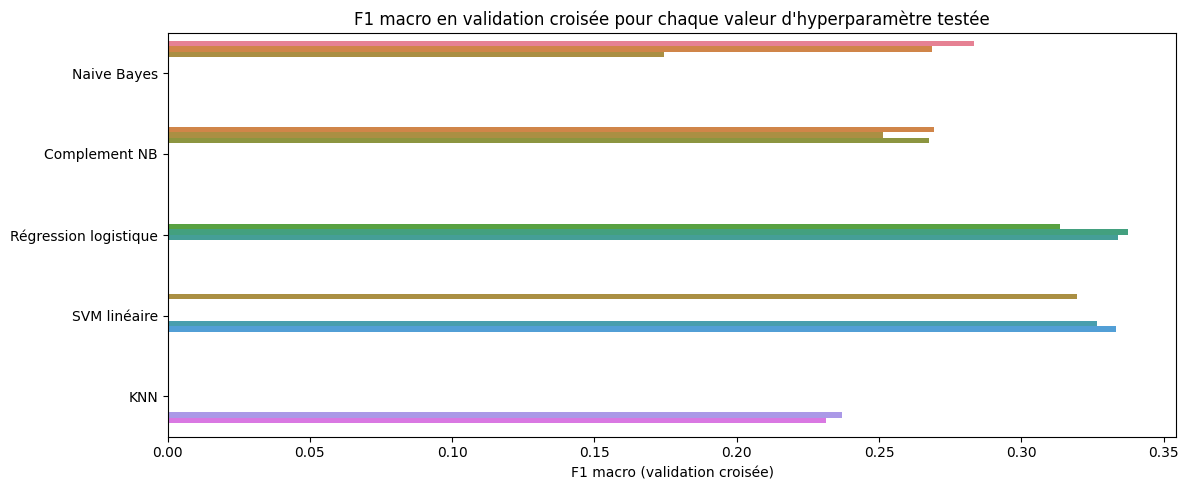

In [22]:
table_ml = pd.DataFrame(resultats).sort_values("F1 macro", ascending=False)
display(table_ml.round(4))

# F1 macro (validation croisée) pour chaque valeur testée
lignes = []
for name, grid in grids.items():
    for params, score in zip(grid.cv_results_["params"], grid.cv_results_["mean_test_score"]):
        lignes.append({"Modèle": name, "Paramètre": str(list(params.values())[0]), "F1 macro": score})

plt.figure(figsize=(12, 5))
sns.barplot(data=pd.DataFrame(lignes), x="F1 macro", y="Modèle", hue="Paramètre", legend=False)
plt.title("F1 macro en validation croisée pour chaque valeur d'hyperparamètre testée")
plt.xlabel("F1 macro (validation croisée)")
plt.ylabel("")
plt.tight_layout()
plt.show()

**Ce qu'on observe :**
- **Tous les modèles font mieux que la baseline** (F1 macro de 0,09), mais les scores restent moyens : 0,36 au mieux. Le problème est difficile, car beaucoup de genres utilisent les mêmes mots, et certaines étiquettes sont fausses.
- Le **SVM linéaire** (0,362 avec C = 0,2) et la **régression logistique** (0,359 avec C = 2) sont devant, presque à égalité. Ce sont les deux modèles qui utilisent `class_weight="balanced"`. La régression logistique retrouve même le mieux les genres rares (meilleure balanced accuracy, 0,41).
- **Naive Bayes** a la meilleure accuracy (environ 59 %), mais un F1 macro plus bas : il répond presque toujours Rock ou Pop, donc il rate les genres rares. **Complement NB** ne fait pas mieux ici.
- **KNN** est le moins bon. Avec 50 000 colonnes, toutes les chansons finissent par paraître à peu près aussi éloignées les unes des autres, et la notion de « voisin » perd son sens.
- Le classement est le même en validation croisée et sur la validation : on peut faire confiance aux réglages choisis.

### 4.5 Et si on avait séparé les données au hasard ?
Pour voir si le découpage par artiste change vraiment quelque chose (partie 2.6), on refait la régression logistique avec un `train_test_split` classique. Cette fois, un même artiste peut se retrouver à la fois dans le train et dans l'évaluation.

In [23]:
X_train_alea, X_val_alea, y_train_alea, y_val_alea = train_test_split(
    df["Lyrics"], df["Genre"], test_size=0.15, random_state=42, stratify=df["Genre"]
)

modele_alea = grids["Régression logistique"].best_estimator_
modele_alea.fit(X_train_alea, y_train_alea)
y_pred_alea = modele_alea.predict(X_val_alea)
print("F1 macro avec un découpage aléatoire  :", round(f1_score(y_val_alea, y_pred_alea, average="macro"), 4))

# On réentraîne sur le vrai train pour retrouver le modèle de la partie 4.3
modele_alea.fit(X_train, y_train)
y_pred = modele_alea.predict(X_val)
print("F1 macro avec un découpage par artiste :", round(f1_score(y_val, y_pred, average="macro"), 4))

F1 macro avec un découpage aléatoire  : 0.3629
F1 macro avec un découpage par artiste : 0.3586


Avec un découpage au hasard, le score est **un tout petit peu meilleur** (moins de 0,01 d'écart). Ici, l'effet « le modèle reconnaît l'artiste » existe, mais il est faible. On garde quand même le découpage par artiste : c'est celui qui ressemble le plus à l'utilisation réelle de l'application, où les chansons viennent d'artistes inconnus du modèle.

## 5. Deep Learning

Avec le TF-IDF, le modèle voit les paroles comme un simple **sac de mots** : il sait quels mots sont présents, mais pas dans quel ordre (sauf pour les paires de mots). Les réseaux de neurones, eux, peuvent lire le texte **dans l'ordre**. Ils apprennent aussi leur propre façon de représenter chaque mot par une liste de nombres : c'est l'**embedding**.

### 5.1 Préparer les textes pour les réseaux
- `TextVectorization` remplace chaque mot par un **numéro**. On garde les 20 000 mots les plus fréquents, appris **seulement sur le train** (avec `adapt`).
- Tous les textes doivent avoir la même longueur, ici **300 mots** (`MAX_LEN`). On coupe les textes trop longs et on complète les plus courts avec des 0 (le *padding*). Grâce à `mask_zero=True`, le réseau ignore ces 0.
- Les genres sont transformés en nombres avec `LabelEncoder`, comme dans le TP noté.
- On calcule des **poids pour chaque genre**, pour que les genres rares comptent plus pendant l'apprentissage. C'est l'équivalent de `class_weight="balanced"`.

In [24]:
VOCAB_SIZE = 20000
MAX_LEN = 300
EMBED_DIM = 64

tokenizer = layers.TextVectorization(
    max_tokens=VOCAB_SIZE,
    output_sequence_length=MAX_LEN,
    standardize=None   # on lui donne les textes déjà nettoyés
)
tokenizer.adapt(df_train["text_clean"].values)   # appris sur le train uniquement

X_train_pad = tokenizer(df_train["text_clean"].values).numpy()
X_val_pad = tokenizer(df_val["text_clean"].values).numpy()
X_test_pad = tokenizer(df_test["text_clean"].values).numpy()

print("Dimensions après padding :", X_train_pad.shape)
print("Exemple :", X_train_pad[0][:20])

label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train)
y_val_encoded = label_encoder.transform(y_val)

poids = compute_class_weight("balanced", classes=np.unique(y_train_encoded), y=y_train_encoded)
class_weight = dict(enumerate(poids))

print("\nPoids des classes :")
for genre, p in zip(label_encoder.classes_, poids):
    print(f"{genre:8s}: {p:.2f}")

Dimensions après padding : (40186, 300)
Exemple : [  767    48 17443     4    92     4   375    54   280   449     3    31
   140     5   134     4    34    71   200    92]

Poids des classes :
Autres  : 4.29
Folk    : 4.66
Indie   : 4.84
Jazz    : 3.96
Metal   : 1.99
Pop     : 0.39
Rock    : 0.33


### 5.2 Les 4 réseaux testés

Tous les réseaux commencent par une couche **Embedding**, qui transforme chaque mot en une liste de 64 nombres. Ils finissent tous par une couche **Dense avec softmax**, qui a un neurone par genre et donne la probabilité de chaque genre. C'est la version à plusieurs classes de la sigmoïde du TP « adult ».

| Réseau | Comment il fonctionne |
|---|---|
| **MLP** | il fait la moyenne des mots de la chanson, puis passe par une couche cachée. Rapide, mais il ne tient pas compte de l'ordre des mots |
| **RNN** | il lit le texte mot par mot en gardant une mémoire, mais il oublie vite le début du texte |
| **LSTM** | un RNN amélioré, avec une mémoire plus longue |
| **Transformer** | il utilise l'« attention » : chaque mot peut regarder tous les autres mots du texte pour mieux se comprendre |

Réglages communs à tous les réseaux :
- **fonction de perte** : `sparse_categorical_crossentropy`, la version à plusieurs classes de la `binary_crossentropy` des TP ;
- **optimiseur** : Adam ;
- **dropout** de 0,3 : on éteint au hasard 30 % des neurones pendant l'entraînement, pour éviter que le réseau apprenne par cœur ;
- **early stopping** : on arrête l'entraînement dès que le score sur la validation ne s'améliore plus pendant 2 epochs, et on garde la meilleure version du réseau.

In [25]:
def construire_reseau(type_reseau):

    entrees = keras.Input(shape=(MAX_LEN,))

    if type_reseau == "Transformer":
        # embedding des mots + embedding de la position du mot dans le texte
        x = keras_hub.layers.TokenAndPositionEmbedding(
            vocabulary_size=VOCAB_SIZE,
            sequence_length=MAX_LEN,
            embedding_dim=EMBED_DIM,
            mask_zero=True
        )(entrees)
        x = keras_hub.layers.TransformerEncoder(intermediate_dim=128, num_heads=4, dropout=0.1)(x)
        x = layers.GlobalAveragePooling1D()(x)

    else:
        x = layers.Embedding(input_dim=VOCAB_SIZE, output_dim=EMBED_DIM, mask_zero=True)(entrees)

        if type_reseau == "MLP":
            x = layers.GlobalAveragePooling1D()(x)
            x = layers.Dense(64, activation="relu")(x)
        elif type_reseau == "RNN":
            x = layers.SimpleRNN(64)(x)
        elif type_reseau == "LSTM":
            x = layers.LSTM(64)(x)

    x = layers.Dropout(0.3)(x)
    sortie = layers.Dense(len(genres), activation="softmax")(x)  # une probabilité par genre

    modele = keras.Model(entrees, sortie)
    modele.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return modele

### 5.3 Entraînement des réseaux
Attention, cette cellule est longue : environ 1 minute pour le MLP, mais 10 à 25 minutes pour le LSTM et le Transformer sur un ordinateur sans carte graphique.

In [26]:
modeles_neurones = {}
historiques = {}

for nom in ["MLP", "RNN", "LSTM", "Transformer"]:

    print("\nEntraînement du modèle :", nom)

    keras.utils.set_random_seed(42)
    modele = construire_reseau(nom)

    early_stopping = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True
    )

    start = time.perf_counter()
    historique = modele.fit(
        X_train_pad, y_train_encoded,
        validation_data=(X_val_pad, y_val_encoded),
        epochs=8,
        batch_size=128,
        class_weight=class_weight,
        callbacks=[early_stopping],
        verbose=2
    )
    elapsed = time.perf_counter() - start

    # Prédiction sur la validation : on prend le genre le plus probable
    probabilites = modele.predict(X_val_pad, verbose=0)
    y_pred = label_encoder.inverse_transform(probabilites.argmax(axis=1))
    scores = calculer_indicateurs(y_val, y_pred)
    print(scores, f"| {elapsed:.0f} s")

    modeles_neurones[nom] = modele
    historiques[nom] = historique
    resultats.append({"Modèle": nom, "Famille": "DL",
                      "Meilleurs paramètres": f"{len(historique.history['loss'])} epochs",
                      "Temps (s)": elapsed, **scores})


Entraînement du modèle : MLP
Epoch 1/8
314/314 - 10s - 33ms/step - accuracy: 0.2576 - loss: 1.8145 - val_accuracy: 0.2993 - val_loss: 1.7822
Epoch 2/8
314/314 - 7s - 21ms/step - accuracy: 0.3095 - loss: 1.5767 - val_accuracy: 0.2650 - val_loss: 1.7271
Epoch 3/8
314/314 - 7s - 21ms/step - accuracy: 0.3470 - loss: 1.3973 - val_accuracy: 0.2568 - val_loss: 1.7091
Epoch 4/8
314/314 - 7s - 21ms/step - accuracy: 0.3908 - loss: 1.2320 - val_accuracy: 0.2941 - val_loss: 1.6774
Epoch 5/8
314/314 - 6s - 21ms/step - accuracy: 0.4405 - loss: 1.0768 - val_accuracy: 0.2951 - val_loss: 1.6951
Epoch 6/8
314/314 - 7s - 22ms/step - accuracy: 0.4883 - loss: 0.9500 - val_accuracy: 0.3134 - val_loss: 1.7120
{'F1 macro': 0.2544738014915255, 'Balanced accuracy': 0.39491909341975, 'Accuracy': 0.2941030106991789} | 44 s

Entraînement du modèle : RNN
Epoch 1/8
314/314 - 56s - 179ms/step - accuracy: 0.1480 - loss: 1.9574 - val_accuracy: 0.1396 - val_loss: 1.9444
Epoch 2/8
314/314 - 53s - 170ms/step - accuracy: 

### 5.4 Courbes d'apprentissage

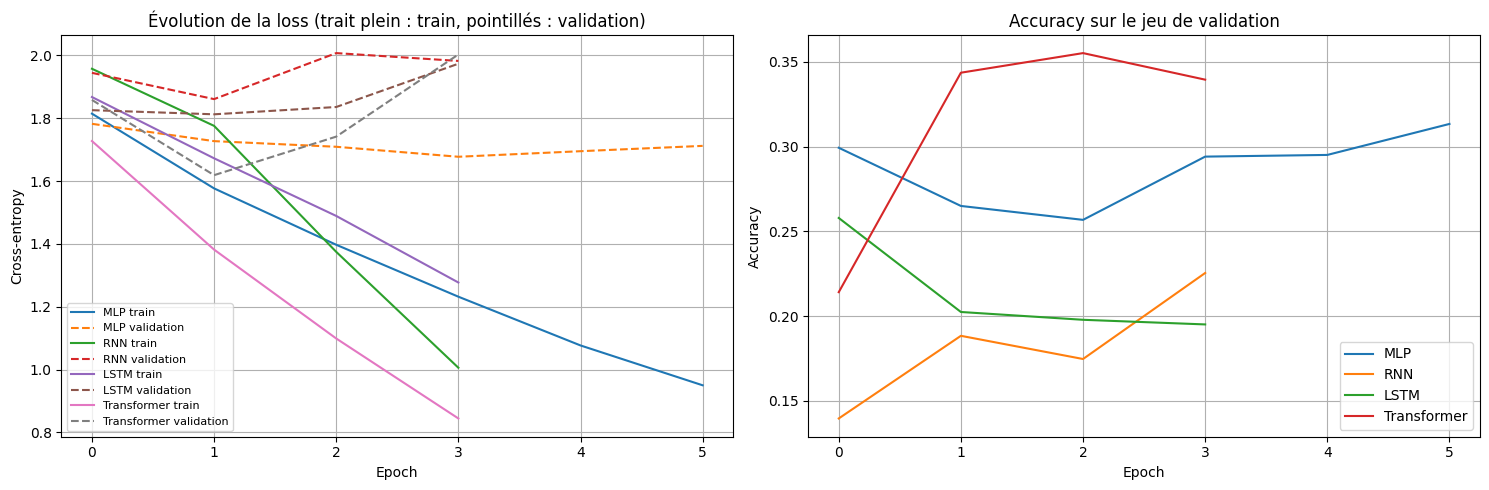

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for nom, historique in historiques.items():
    axes[0].plot(historique.history["loss"], label=nom + " train")
    axes[0].plot(historique.history["val_loss"], linestyle="--", label=nom + " validation")
    axes[1].plot(historique.history["val_accuracy"], label=nom)

axes[0].set_title("Évolution de la loss (trait plein : train, pointillés : validation)")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy")
axes[0].legend(fontsize=8)
axes[0].grid()

axes[1].set_title("Accuracy sur le jeu de validation")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid()

plt.tight_layout()
plt.show()

**Ce que montrent les courbes :**
- **Les réseaux ont du mal.** Sur le train, l'erreur (la *loss*) baisse vite. Mais sur la validation, elle baisse peu, puis remonte. C'est le signe que les réseaux **apprennent par cœur** les chansons du train au lieu d'apprendre des règles générales. Ils ont beaucoup de paramètres à régler (rien que l'embedding : 20 000 mots × 64 nombres) pour seulement 40 000 chansons. L'early stopping les arrête après 4 à 6 epochs.
- Le **Transformer** est le meilleur réseau (F1 macro d'environ 0,28), devant le **MLP** (environ 0,25). Le **LSTM** et le **RNN** font nettement moins bien : sur des textes de 300 mots, ils ont du mal à se souvenir du début.
- Les réseaux ont une **accuracy basse** (20 à 35 %), mais une balanced accuracy correcte (jusqu'à 0,39). À cause des poids de classes, ils proposent souvent des genres rares, et se trompent alors sur beaucoup de chansons Rock et Pop.
- Ils sont aussi **lents** : plus de 10 minutes pour le LSTM et le Transformer.
- On aurait pu essayer **BERT** (en version multilingue), mais il est beaucoup trop lent sans carte graphique. Dans le TP IMDB, la petite version anglaise de BERT prenait déjà environ 100 secondes par epoch pour seulement 5 000 textes.

## 6. Comparaison de tous les modèles
On met tous les modèles côte à côte, avec leurs scores sur la validation.

In [28]:
table_resultats = pd.DataFrame(resultats).sort_values("F1 macro", ascending=False).reset_index(drop=True)
display(table_resultats.round(4))

,Modèle,Famille,Meilleurs paramètres,Temps (s),F1 macro,Balanced accuracy,Accuracy
0,SVM linéaire,ML,{'classifier__C': 0.2},121.9159,0.3624,0.3932,0.5636
1,Régression logistique,ML,{'classifier__C': 2.0},237.9865,0.3586,0.4065,0.5309
2,Naive Bayes,ML,{'classifier__alpha': 0.01},102.7965,0.3199,0.3036,0.5867
3,Complement NB,ML,{'classifier__alpha': 0.1},97.3547,0.2888,0.3028,0.5740
4,Transformer,DL,4 epochs,826.5459,0.2755,0.3851,0.3436
5,KNN,ML,{'classifier__n_neighbors': 5},177.2815,0.2689,0.2559,0.5223
6,MLP,DL,6 epochs,44.3548,0.2545,0.3949,0.2941
7,LSTM,DL,4 epochs,608.6766,0.1784,0.3276,0.2024
8,RNN,DL,4 epochs,219.0812,0.1468,0.2645,0.1884
9,Baseline,Référence,-,0.0000,0.0863,0.1429,0.4324


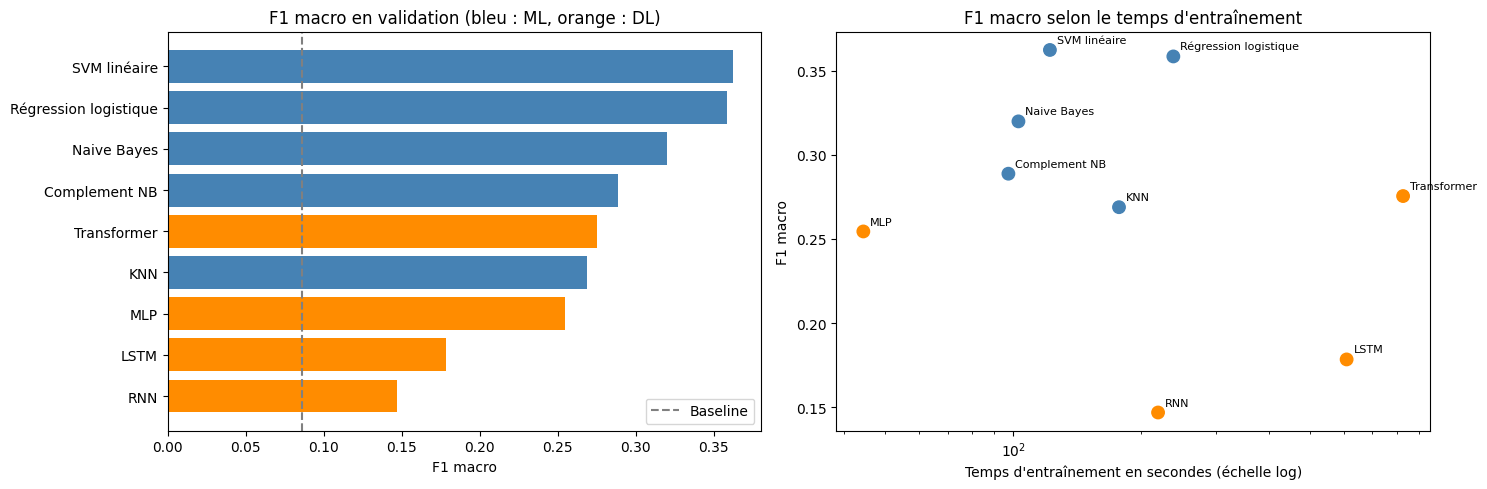

In [29]:
table_graph = table_resultats[table_resultats["Famille"] != "Référence"]
couleurs = table_graph["Famille"].map({"ML": "steelblue", "DL": "darkorange"})

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].barh(table_graph["Modèle"], table_graph["F1 macro"], color=couleurs)
axes[0].axvline(scores_baseline["F1 macro"], color="grey", linestyle="--", label="Baseline")
axes[0].invert_yaxis()
axes[0].set_title("F1 macro en validation (bleu : ML, orange : DL)")
axes[0].set_xlabel("F1 macro")
axes[0].legend()

axes[1].scatter(table_graph["Temps (s)"], table_graph["F1 macro"], c=couleurs, s=80)
for i, ligne in table_graph.iterrows():
    axes[1].annotate(ligne["Modèle"], (ligne["Temps (s)"], ligne["F1 macro"]), xytext=(5, 5),
                     textcoords="offset points", fontsize=8)
axes[1].set_xscale("log")
axes[1].set_title("F1 macro selon le temps d'entraînement")
axes[1].set_xlabel("Temps d'entraînement en secondes (échelle log)")
axes[1].set_ylabel("F1 macro")

plt.tight_layout()
plt.show()

**Ce qu'on retient :**
- **Les modèles « classiques » sur TF-IDF gagnent nettement.** Le SVM et la régression logistique ont un F1 macro d'environ 0,36. Le meilleur réseau de neurones, le Transformer, est à environ 0,28, derrière Naive Bayes.
- Ils sont aussi **bien plus rapides** : quelques minutes pour tout régler, alors qu'un seul entraînement de LSTM ou de Transformer prend plus de 10 minutes.
- On retrouve ce qu'on avait vu dans les TP « adult » et IMDB : **un modèle plus compliqué n'est pas forcément meilleur**, surtout quand certains genres ont peu d'exemples.
- Pour deviner le genre, ce qui compte surtout, ce sont **les mots utilisés**, et le TF-IDF les capte déjà bien. L'ordre des mots apporte peu.

## 7. Choix du modèle final

### 7.1 Comment on choisit
**Le critère principal**, c'est le F1 macro sur la validation.

Mais pour l'application, on veut aussi un modèle qui :
1. donne une **probabilité** pour chaque genre, puisque l'application doit l'afficher ;
2. soit **léger**, pour se charger vite et être facile à mettre en ligne ;
3. soit **facile à expliquer** : avec un modèle linéaire, on peut montrer quels mots ont fait pencher la décision.

**Notre règle :** si plusieurs modèles sont à **moins de 0,01** du meilleur score, on considère qu'ils sont à égalité, car une si petite différence peut être due au hasard. Dans ce cas, on prend la **régression logistique**, qui donne directement des probabilités.

**Pourquoi pas le SVM, alors qu'il est premier ?** Le SVM ne donne pas de probabilités. Pour en obtenir, il faut l'entourer de `CalibratedClassifierCV`. On l'a essayé, et le SVM ainsi modifié ne proposait **plus jamais** les genres rares (Autres, Folk, Indie) : son F1 macro sur le test tombait à 0,30.

In [30]:
table_modeles = table_resultats[table_resultats["Famille"] != "Référence"]
best_score = table_modeles.iloc[0]["F1 macro"]

# Modèles à moins de 0,01 du meilleur F1 macro
modeles_proches = table_modeles[table_modeles["F1 macro"] >= best_score - 0.01]
print("Modèles à moins de 0,01 du meilleur :")
display(modeles_proches[["Modèle", "Famille", "F1 macro"]].round(4))

if "Régression logistique" in modeles_proches["Modèle"].values:
    best_name = "Régression logistique"
else:
    best_name = table_modeles.iloc[0]["Modèle"]

best_family = table_modeles[table_modeles["Modèle"] == best_name]["Famille"].values[0]
print("\nModèle retenu :", best_name, f"({best_family})")

Modèles à moins de 0,01 du meilleur :


,Modèle,Famille,F1 macro
0,SVM linéaire,ML,0.3624
1,Régression logistique,ML,0.3586



Modèle retenu : Régression logistique (ML)


### 7.2 Entraînement du modèle final sur train + validation

Maintenant que les réglages sont choisis, on **réentraîne le modèle sur le train et la validation réunis**. Il apprend ainsi sur plus de chansons. Le test, lui, reste toujours de côté.

Le modèle contient toutes les étapes : **nettoyage, puis TF-IDF, puis régression logistique**. Pour prédire le genre de nouvelles paroles, l'application n'aura qu'à appeler `best_model.predict_proba(["paroles"])`.

Le code prévoit aussi les autres cas, au cas où les résultats seraient différents : si un SVM était choisi, on l'entourerait de `CalibratedClassifierCV`, et si un réseau de neurones gagnait, on lui ajouterait le `tokenizer` pour qu'il accepte directement du texte.

In [31]:
X_train_full = pd.concat([X_train, X_val])
y_train_full = pd.concat([y_train, y_val])

if best_family == "ML":

    best_model = grids[best_name].best_estimator_

    if not hasattr(best_model, "predict_proba"):   # cas du SVM
        svm = best_model.named_steps["classifier"]
        best_model.set_params(classifier=CalibratedClassifierCV(svm, cv=3))

    best_model.fit(X_train_full, y_train_full)
    classes = list(best_model.classes_)
    proba_test = best_model.predict_proba(X_test)

else:
    reseau = modeles_neurones[best_name]
    entree_texte = keras.Input(shape=(1,), dtype="string")
    best_model = keras.Model(entree_texte, reseau(tokenizer(entree_texte)))
    classes = list(label_encoder.classes_)
    proba_test = best_model.predict(np.array([[t] for t in df_test["text_clean"]]), verbose=0)

print("Modèle final entraîné. Classes :", classes)

Modèle final entraîné. Classes : ['Autres', 'Folk', 'Indie', 'Jazz', 'Metal', 'Pop', 'Rock']


### 7.3 Le score final, sur le test
Jusqu'ici, on n'a jamais utilisé le test : ni pour choisir le modèle, ni pour régler ses paramètres. Son score est donc une **mesure honnête** de ce que donnera le modèle sur des chansons d'artistes qu'il ne connaît pas.

In [32]:
y_pred_test = np.array(classes)[proba_test.argmax(axis=1)]

scores_test = calculer_indicateurs(y_test, y_pred_test)
print("Performances sur le test :", {k: round(v, 4) for k, v in scores_test.items()})

print("\nRapport de classification sur le jeu de test :")
print(classification_report(y_test, y_pred_test, digits=3, zero_division=0))

Performances sur le test : {'F1 macro': 0.3392, 'Balanced accuracy': 0.3863, 'Accuracy': 0.5177}

Rapport de classification sur le jeu de test :
              precision    recall  f1-score   support

      Autres      0.081     0.116     0.095       267
        Folk      0.104     0.171     0.129       246
       Indie      0.101     0.148     0.120       237
        Jazz      0.293     0.490     0.366       290
       Metal      0.341     0.677     0.454       579
         Pop      0.699     0.591     0.640      2943
        Rock      0.639     0.513     0.569      3475

    accuracy                          0.518      8037
   macro avg      0.323     0.386     0.339      8037
weighted avg      0.577     0.518     0.537      8037



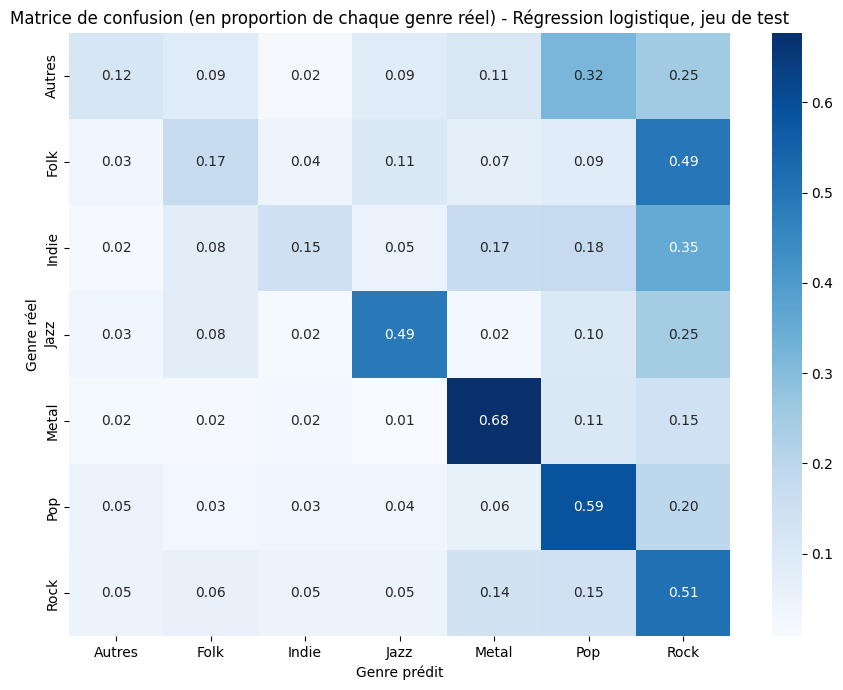

In [33]:
cm = confusion_matrix(y_test, y_pred_test, labels=classes, normalize="true")

plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=classes, yticklabels=classes)
plt.title(f"Matrice de confusion (en proportion de chaque genre réel) - {best_name}, jeu de test")
plt.xlabel("Genre prédit")
plt.ylabel("Genre réel")
plt.tight_layout()
plt.show()

In [34]:
# Les probabilités sont-elles utiles ? On regarde l'accuracy quand le modèle est sûr de lui
proba_max = proba_test.max(axis=1)
bonnes_reponses = (y_pred_test == y_test.values)

for seuil in [0.3, 0.5, 0.7]:
    selection = proba_max >= seuil
    print(f"Probabilité >= {seuil} : {selection.mean():.0%} des chansons, accuracy = {bonnes_reponses[selection].mean():.1%}")

Probabilité >= 0.3 : 86% des chansons, accuracy = 54.8%
Probabilité >= 0.5 : 34% des chansons, accuracy = 69.1%
Probabilité >= 0.7 : 12% des chansons, accuracy = 82.0%


**Ce qu'on observe sur le test :**
- Le **F1 macro est de 0,339**, proche de celui de la validation (0,359). Une petite baisse est normale. Le score n'a pas été « gonflé » par nos choix, on peut s'y fier.
- Le modèle a **52 % de bonnes réponses** (contre 43 % pour la baseline), et une balanced accuracy de 0,39 (contre 0,14).
- **Les genres les mieux reconnus** sont Pop (F1 de 0,64), Rock (0,57), Metal (0,45) et Jazz (0,37).
- **Autres, Folk et Indie restent difficiles**, avec un F1 entre 0,10 et 0,13. Le modèle les propose assez souvent, mais il se trompe souvent quand il le fait : beaucoup de ces prédictions sont en fait des chansons Pop ou Rock. C'est l'effet de `class_weight="balanced"`, qui pousse le modèle à proposer les genres rares. C'est un compromis : sans ce réglage, il ne les proposerait presque jamais (c'est ce qui se passe avec Naive Bayes ou avec le SVM calibré).
- **La probabilité affichée a du sens** : quand le modèle est sûr à plus de 50 %, il a raison 69 % du temps, et à plus de 70 %, il a raison 82 % du temps. C'est pour ça que l'application affiche la probabilité, et prévient quand le modèle hésite.

### 7.4 Quels mots font pencher la décision ?
Dans une régression logistique, chaque mot a un **coefficient** pour chaque genre. Plus le coefficient est grand, plus la présence de ce mot pousse le modèle vers ce genre. On affiche les 10 mots les plus importants de chaque genre.

In [35]:
classifier = best_model.named_steps["classifier"] if best_family == "ML" else None

if hasattr(classifier, "coef_"):
    feature_names = best_model.named_steps["tfidf"].get_feature_names_out()
    for i, genre in enumerate(classifier.classes_):
        top_indices = classifier.coef_[i].argsort()[::-1][:10]
        print(f"{genre:8s}: {', '.join(feature_names[top_indices])}")
else:
    print("Le modèle retenu n'a pas de coefficients à afficher.")

Autres  : is my, even, bitch, girl, im, dolly, you feel, about, true love, rap
Folk    : and the, train, we could, mo, bright, lonesome, pretty, town, graveyard, long
Indie   : you said, sirens, from the, its, know about, up for, not you, scene, jungle, drag
Jazz    : romance, thrill, love, dear, lovely, that, baby, blue, why, may
Metal   : fucking, hell, fuck, hate, death, dead, metal, die, pain, blood
Pop     : wanna, nigga, amor, gon, chorus, paixão, saudade, ohh, cuz, tryna
Rock    : music by, well, away the, words music, all right, yeah, she, say you, cos, gonna


Les mots trouvés sont plutôt logiques :
- **Metal** : *hell, death, dead, pain, blood*. **Jazz** : *romance, thrill, dear, lovely, blue*. **Folk** : *train, lonesome, town, graveyard*. Ces mots collent bien à l'ambiance de chaque genre.
- **Pop** : on y trouve des mots de rap (*nigga, gon, tryna*) et des mots portugais (*amor, paixão, saudade*). Ce sont les conséquences directes des étiquettes fausses (partie 2.7) et du fait que les chansons en portugais sont presque toutes Pop.
- **Autres** : des mots de rap (*bitch, rap*) et *dolly* (pour Dolly Parton, une chanteuse de Country). C'est cohérent, puisque cette classe réunit Hip-Hop, Country, R&B et Electronic.
- Certains mots ne parlent pas du tout de musique, comme *music by* ou *words music* pour Rock. Ce sont des crédits recopiés avec les paroles sur certains sites. Le modèle se sert un peu de ces détails, qui n'ont rien à voir avec le genre.

## 8. Sauvegarde du modèle

On enregistre dans un dossier `models/` :
- **le modèle complet** (`modele_genre.joblib`) : il contient le nettoyage, le TF-IDF et la régression logistique ;
- **`metadata.json`** : le nom du modèle, la liste des genres, les scores et les versions des librairies. L'application lit ce fichier pour afficher ces informations ;
- **`comparaison_modeles.csv`** : le tableau qui compare tous les modèles.

La fonction de nettoyage, elle, est déjà dans `pretraitement.py`.

In [36]:
import os
os.makedirs("models", exist_ok=True)

if best_family == "ML":
    fichier = "modele_genre.joblib"
    joblib.dump(best_model, "models/" + fichier, compress=3)
    type_modele = "sklearn"
else:
    fichier = "modele_genre.keras"
    best_model.save("models/" + fichier)
    type_modele = "keras"

rapport = classification_report(y_test, y_pred_test, output_dict=True, zero_division=0)

metadata = {
    "nom_modele": best_name,
    "type": type_modele,
    "fichier": fichier,
    "classes": classes,
    "genres_regroupes_dans_autres": genres_rares,
    "scores_test": {k: round(float(v), 4) for k, v in scores_test.items()},
    "f1_test_par_genre": {g: round(rapport[g]["f1-score"], 4) for g in classes},
    "nb_chansons_entrainement": len(y_train_full),
    "dataset": "perceptron-743/music-multi-lingual",
    "versions": {"python": platform.python_version(), "scikit-learn": sklearn.__version__,
                 "tensorflow": tf.__version__},
}

with open("models/metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2, ensure_ascii=False)

table_resultats["Meilleurs paramètres"] = table_resultats["Meilleurs paramètres"].astype(str)
table_resultats.round(4).to_csv("models/comparaison_modeles.csv", index=False)

print("Modèle sauvegardé :", "models/" + fichier,
      f"({os.path.getsize('models/' + fichier) / 1e6:.1f} Mo)")
print(json.dumps(metadata, indent=2, ensure_ascii=False))

Modèle sauvegardé : models/modele_genre.joblib (3.3 Mo)
{
  "nom_modele": "Régression logistique",
  "type": "sklearn",
  "fichier": "modele_genre.joblib",
  "classes": [
    "Autres",
    "Folk",
    "Indie",
    "Jazz",
    "Metal",
    "Pop",
    "Rock"
  ],
  "genres_regroupes_dans_autres": [
    "R&B",
    "Hip-Hop",
    "Electronic",
    "Country"
  ],
  "scores_test": {
    "F1 macro": 0.3392,
    "Balanced accuracy": 0.3863,
    "Accuracy": 0.5177
  },
  "f1_test_par_genre": {
    "Autres": 0.0954,
    "Folk": 0.1292,
    "Indie": 0.1203,
    "Jazz": 0.3665,
    "Metal": 0.4537,
    "Pop": 0.6404,
    "Rock": 0.5689
  },
  "nb_chansons_entrainement": 48224,
  "dataset": "perceptron-743/music-multi-lingual",
  "versions": {
    "python": "3.13.5",
    "scikit-learn": "1.8.0",
    "tensorflow": "2.20.0"
  }
}


### Vérification : on recharge le modèle et on l'essaie
On recharge le fichier sauvegardé, comme le fera l'application, et on lui donne quelques paroles inventées.

In [37]:
exemples = [
    "Darkness falls upon the burning souls, blood and fire, the demons rise from hell, death will reign eternal",
    "The moon is shining, my darling, dance with me tonight, so lovely, so heavenly, your sweet romance",
    "Meu amor, eu sinto saudade de você, a nossa paixão não vai acabar, quero te ver todo dia",
    "Yo, I'm rollin' through the hood with my homies, money on my mind, spittin' rhymes on the mic, haters gonna hate",
]

if type_modele == "sklearn":
    modele_charge = joblib.load("models/" + fichier)
    probas = modele_charge.predict_proba(exemples)
else:
    modele_charge = keras.models.load_model("models/" + fichier)
    probas = modele_charge.predict(np.array([[nettoyer_texte(t)] for t in exemples]), verbose=0)

for texte, proba in zip(exemples, probas):
    i = proba.argmax()
    print(f"{classes[i]:8s} ({proba[i]:.0%}) <- {texte[:60]}...")

Metal    (96%) <- Darkness falls upon the burning souls, blood and fire, the d...
Jazz     (97%) <- The moon is shining, my darling, dance with me tonight, so l...
Pop      (74%) <- Meu amor, eu sinto saudade de você, a nossa paixão não vai a...
Autres   (31%) <- Yo, I'm rollin' through the hood with my homies, money on my...


Le modèle rechargé fonctionne bien sur du texte brut :
- les paroles avec un vocabulaire typique sont reconnues avec une **forte probabilité** : Metal (96 %), Jazz (97 %), et Pop pour le texte en portugais (74 %) ;
- les paroles de rap vont bien dans **Autres** (où se trouve le Hip-Hop), mais avec une **probabilité faible** (31 %). C'est à cause des rappeurs classés Pop dans le dataset.

Le modèle est prêt. Dans la suite, on le met dans une application web.

## 9. L'application web avec Streamlit

Le modèle est sauvegardé. Maintenant, on veut que **n'importe qui puisse l'utiliser**, depuis un navigateur, sans toucher à Python. Pour ça, on utilise **Streamlit** : avec quelques lignes de Python, on obtient une vraie page web.

**Comment ça marche :** l'application charge le modèle sauvegardé en partie 8, une seule fois au démarrage, grâce à `@st.cache_resource`. Ensuite, à chaque clic, elle demande au modèle de deviner le genre des paroles tapées, et elle affiche le résultat. Le modèle étant petit (quelques Mo), il se charge en moins d'une seconde.

### Les fichiers du projet
```
TP Music Classification/
├── projet_genre_musical.ipynb      # ce notebook : tout le projet
├── pretraitement.py                # la fonction de nettoyage (créée en partie 3)
├── app.py                          # l'application Streamlit (créée en partie 9)
├── requirements.txt                # les librairies à installer sur le serveur (partie 10)
├── docs/                           # la version page web, pour GitHub Pages (partie 10)
│   └── modele.json                 # les nombres du modèle (créé en partie 10)
├── .github/workflows/
│   └── deployer-site.yml           # met la page web en ligne à chaque git push
└── models/                         # créé en partie 8
    ├── modele_genre.joblib         # le modèle complet : nettoyage + TF-IDF + régression logistique
    ├── metadata.json               # les genres, les scores, les versions
    └── comparaison_modeles.csv     # le tableau de comparaison des modèles
```

### 9.1 Ce que fait l'application
- **on donne les paroles** : soit on les écrit (ou on les colle) dans une zone de texte, soit on importe un fichier `.txt`. Des exemples sont proposés pour essayer rapidement ;
- **elle affiche le résultat** : le genre deviné, sa probabilité, un graphique avec la probabilité de chaque genre, et les mots qui ont fait pencher la décision ;
- **elle prévient l'utilisateur** si le texte est vide, s'il est très court, ou si le modèle hésite entre deux genres ;
- **sur le côté**, elle présente le modèle : son nom, ses scores, les genres possibles, et le tableau de comparaison des modèles.

Comme pour `pretraitement.py`, la cellule suivante écrit le code dans un fichier, `app.py`, grâce à `%%writefile`.

In [38]:
%%writefile app.py
import json

import altair as alt
import joblib
import numpy as np
import pandas as pd
import streamlit as st

from pretraitement import nettoyer_texte

SEUIL = 0.40       # en dessous de cette probabilité, on prévient que le modèle hésite
MOTS_MINIMUM = 20  # en dessous de ce nombre de mots, on prévient que le texte est court

exemples = {
    "(aucun)": "",
    "Metal": "Darkness falls upon the burning souls, blood and fire, the demons rise from hell, "
             "death will reign eternal in the kingdom of the damned, screaming in the void",
    "Jazz": "The moon is shining, my darling, dance with me tonight, so lovely, so heavenly, "
            "your sweet romance, a thrill I can't resist, sentimental dreams of you and me",
    "Rock": "Well all right, she's a woman on the highway, jack is drivin' all night long, "
            "rock and roll is here to stay, say you will, babe",
    "Folk": "Down by the river in the little town, my darling with a ribbon in her hair, "
            "we walked past the graveyard gates on a bright morning",
    "Pop (portugais)": "Meu amor, eu sinto saudade de você, a nossa paixão não vai acabar, "
                       "quero te ver todo dia, coração apaixonado",
}

st.set_page_config(page_title="Genre musical", page_icon="🎵")


@st.cache_resource   # le modèle n'est chargé qu'une seule fois
def charger_modele():
    with open("models/metadata.json", encoding="utf-8") as f:
        metadata = json.load(f)
    modele = joblib.load("models/" + metadata["fichier"])
    return modele, metadata


def mots_importants(texte, modele, genre):
    # Pour chaque mot du texte : son poids TF-IDF x son coefficient pour le genre prédit
    tfidf = modele.named_steps["tfidf"]
    classifier = modele.named_steps["classifier"]
    if not hasattr(classifier, "coef_"):
        return []
    i = list(classifier.classes_).index(genre)
    contributions = tfidf.transform([texte]).toarray()[0] * classifier.coef_[i]
    feature_names = tfidf.get_feature_names_out()
    top_indices = contributions.argsort()[::-1][:8]
    return [feature_names[j] for j in top_indices if contributions[j] > 0]


modele, metadata = charger_modele()

# ---------- Barre latérale : présentation du modèle
with st.sidebar:
    st.header("À propos du modèle")
    st.write("**Modèle :**", metadata["nom_modele"])
    st.write("**Chansons d'entraînement :**", str(metadata["nb_chansons_entrainement"]))
    col1, col2 = st.columns(2)
    col1.metric("F1 macro (test)", f"{metadata['scores_test']['F1 macro']:.2f}")
    col2.metric("Accuracy (test)", f"{metadata['scores_test']['Accuracy']:.0%}")
    st.write("**Genres possibles :**", ", ".join(metadata["classes"]))
    st.caption("« Autres » regroupe : " + ", ".join(metadata["genres_regroupes_dans_autres"]) + ".")
    st.caption("Données : " + metadata["dataset"] + " (Hugging Face). Paroles en anglais, portugais, roumain ou allemand.")
    with st.expander("Comparaison des modèles testés"):
        comparaison = pd.read_csv("models/comparaison_modeles.csv")
        st.dataframe(comparaison[["Modèle", "Famille", "F1 macro", "Accuracy"]], hide_index=True)

# ---------- Page principale
st.title("🎵 Quel est le genre de cette chanson ?")
st.write("Collez les **paroles** d'une chanson, ou importez un fichier texte : "
         "le modèle devine son **genre musical** et donne la probabilité associée.")

onglet_texte, onglet_fichier = st.tabs(["✍️ Écrire / coller", "📄 Importer un fichier .txt"])

with onglet_texte:
    choix = st.selectbox("Charger un exemple (facultatif)", list(exemples))
    texte_saisi = st.text_area("Paroles", value=exemples[choix], height=220,
                               placeholder="Collez ici les paroles de la chanson...")

with onglet_fichier:
    fichier = st.file_uploader("Fichier texte contenant les paroles", type=["txt"])
    texte_fichier = ""
    if fichier is not None:
        contenu = fichier.getvalue()
        try:
            texte_fichier = contenu.decode("utf-8")
        except UnicodeDecodeError:
            texte_fichier = contenu.decode("latin-1")
        st.text_area("Aperçu du fichier", texte_fichier[:2000], height=150, disabled=True)

# Si un fichier est importé, on utilise son texte, sinon le texte saisi
texte = texte_fichier if texte_fichier.strip() else texte_saisi

if st.button("Prédire le genre", type="primary"):

    nb_mots = len(nettoyer_texte(texte).split())

    if nb_mots == 0:
        st.error("Le texte est vide. Écrivez ou collez des paroles.")
    else:
        if nb_mots < MOTS_MINIMUM:
            st.warning(f"Le texte ne contient que {nb_mots} mots : la prédiction sera peu fiable.")

        probas = modele.predict_proba([texte])[0]
        probas = pd.Series(probas, index=modele.classes_).sort_values(ascending=False)
        genre = probas.index[0]
        proba = probas.iloc[0]

        st.subheader("Résultat")
        col1, col2 = st.columns(2)
        col1.metric("Genre prédit", genre)
        col2.metric("Probabilité", f"{proba:.1%}")

        if proba < SEUIL:
            st.info(f"Le modèle hésite avec **{probas.index[1]}** ({probas.iloc[1]:.1%}). "
                    "Les paroles de Pop, Rock, Indie et Folk se ressemblent beaucoup.")

        st.write("**Probabilité de chaque genre :**")
        tableau = pd.DataFrame({"Genre": probas.index, "Probabilité": probas.values})
        graphique = alt.Chart(tableau).mark_bar().encode(
            x=alt.X("Probabilité", axis=alt.Axis(format="%")),
            y=alt.Y("Genre", sort="-x", title=None),   # du plus probable au moins probable
        )
        st.altair_chart(graphique, use_container_width=True)

        mots = mots_importants(texte, modele, genre)
        if mots:
            st.write(f"**Mots qui orientent vers {genre} :**", ", ".join(mots))

st.caption("Projet de Machine Learning (NLP). Le genre dépend aussi de la musique : "
           "les paroles seules ne suffisent pas toujours.")

Overwriting app.py


### 9.2 On teste l'application automatiquement
Streamlit propose `AppTest`, qui fait tourner l'application **sans ouvrir de navigateur**. On fait comme si un utilisateur :
1. cliquait sur « Prédire » sans avoir rien écrit : l'application doit afficher un message d'erreur ;
2. collait des paroles de metal puis cliquait sur « Prédire » : l'application doit afficher le genre et sa probabilité.

In [39]:
from streamlit.testing.v1 import AppTest

app = AppTest.from_file("app.py", default_timeout=120)
app.run()
print("L'application démarre sans erreur :", len(app.exception) == 0)
print("Titre :", app.title[0].value)

# Test 1 : texte vide
app.button[0].click().run()
print("\nTest texte vide ->", app.error[0].value)

# Test 2 : des paroles de metal
app.text_area[0].input("Darkness falls upon the burning souls, blood and fire, the demons rise from hell").run()
app.button[0].click().run()
print("\nErreurs pendant l'exécution :", len(app.exception))
for metric in app.metric:
    print(metric.label, ":", metric.value)

2026-11-20 15:11:48.039 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.



L'application démarre sans erreur : True
Titre : 🎵 Quel est le genre de cette chanson ?

Test texte vide -> Le texte est vide. Écrivez ou collez des paroles.

Erreurs pendant l'exécution : 0
Genre prédit : Metal
Probabilité : 83.8%
F1 macro (test) : 0.34
Accuracy (test) : 52%


### 9.3 On lance l'application sur l'ordinateur
La cellule suivante démarre l'application. Il suffit ensuite d'ouvrir **http://localhost:8501** dans le navigateur.

Pour faire la même chose dans un terminal, depuis le dossier du projet : `streamlit run app.py`

In [40]:
import subprocess
import sys

serveur = subprocess.Popen([sys.executable, "-m", "streamlit", "run", "app.py",
                            "--server.headless", "true", "--server.port", "8501"])
print("Application lancée : ouvrir http://localhost:8501")

Application lancée : ouvrir http://localhost:8501


In [41]:
# Arrêter l'application quand on a fini
serveur.terminate()
print("Application arrêtée.")

Application arrêtée.


## 10. La mise en ligne

Pour l'instant, l'application ne marche que sur notre ordinateur. Pour qu'elle soit accessible à tout le monde via un lien, on propose **deux façons** de la publier, toutes les deux gratuites et à partir d'un dépôt **GitHub** :

| | Streamlit Community Cloud | GitHub Pages |
|---|---|---|
| Ce qui est en ligne | l'application Streamlit (`app.py`) | une page web (`docs/index.html` + `docs/app.js`) |
| Où tourne le modèle | sur un serveur, en Python | **directement dans le navigateur**, en JavaScript |
| Lien obtenu | `https://nom-de-l-app.streamlit.app` | `https://votre-pseudo.github.io/nom-du-depot/` |
| Mise à jour | automatique à chaque `git push` | automatique à chaque `git push` |

**Pourquoi deux versions ?** GitHub Pages ne sait afficher que des pages web « fixes » (HTML, CSS, JavaScript) : il ne peut pas faire tourner Python, donc ni Streamlit ni scikit-learn. Mais notre modèle est une régression logistique : pour prédire, il suffit de nettoyer le texte, de calculer le TF-IDF, puis de faire des multiplications et des additions. On peut donc **exporter les nombres du modèle** dans un fichier, et refaire ces calculs en JavaScript dans le navigateur. Avantage : la page s'ouvre instantanément, sans serveur à réveiller.

### 10.1 Le fichier requirements.txt (pour Streamlit Cloud)
Le serveur doit savoir quelles librairies installer. On note les **mêmes versions** que celles utilisées pour entraîner le modèle. C'est surtout important pour scikit-learn : un modèle sauvegardé avec une version de scikit-learn peut refuser de se recharger avec une autre.

In [42]:
import os
import altair, pandas, streamlit

lignes = [
    "streamlit==" + streamlit.__version__,
    "altair==" + altair.__version__,
    "scikit-learn==" + sklearn.__version__,
    "joblib==" + joblib.__version__,
    "numpy==" + np.__version__,
    "pandas==" + pandas.__version__,
]

with open("requirements.txt", "w") as f:
    f.write("\n".join(lignes) + "\n")

print(open("requirements.txt").read())
print("Version de Python à choisir sur Streamlit Cloud :", platform.python_version()[:4])
print(f"Taille du modèle : {os.path.getsize('models/' + fichier) / 1e6:.1f} Mo (GitHub accepte jusqu'à 100 Mo par fichier)")

streamlit==1.45.1
altair==5.5.0
scikit-learn==1.8.0
joblib==1.5.3
numpy==2.4.1
pandas==3.0.0

Version de Python à choisir sur Streamlit Cloud : 3.13
Taille du modèle : 3.3 Mo (GitHub accepte jusqu'à 100 Mo par fichier)


### 10.2 Exporter le modèle pour la page web (GitHub Pages)

On enregistre dans `docs/modele.json` tout ce dont `app.js` a besoin pour refaire la prédiction :
- le **vocabulaire** du TF-IDF : à chaque mot (ou paire de mots), son numéro de colonne ;
- les **poids idf** de chaque mot ;
- les **coefficients** et les **intercepts** de la régression logistique : un coefficient par mot et par genre ;
- quelques **informations** sur le modèle (nom, scores, genres), affichées sur la page.

On arrondit les nombres à 5 chiffres après la virgule pour que le fichier reste léger.

In [43]:
tfidf_final = best_model.named_steps["tfidf"]
classifier_final = best_model.named_steps["classifier"]

modele_web = {
    "classes": [str(c) for c in classifier_final.classes_],
    "vocabulaire": {mot: int(colonne) for mot, colonne in tfidf_final.vocabulary_.items()},
    "idf": np.round(tfidf_final.idf_, 5).tolist(),
    "coef": np.round(classifier_final.coef_, 5).tolist(),
    "intercept": np.round(classifier_final.intercept_, 5).tolist(),
    "infos": {
        "nom_modele": metadata["nom_modele"],
        "scores_test": metadata["scores_test"],
        "genres_regroupes_dans_autres": metadata["genres_regroupes_dans_autres"],
        "nb_chansons_entrainement": metadata["nb_chansons_entrainement"],
        "dataset": metadata["dataset"],
    },
}

os.makedirs("docs", exist_ok=True)
with open("docs/modele.json", "w", encoding="utf-8") as f:
    json.dump(modele_web, f, ensure_ascii=False, separators=(",", ":"))

print(f"docs/modele.json : {os.path.getsize('docs/modele.json') / 1e6:.1f} Mo")
print("Nombre de mots dans le vocabulaire :", len(modele_web["vocabulaire"]))

docs/modele.json : 4.2 Mo
Nombre de mots dans le vocabulaire : 50000


**On vérifie que le calcul « à la main » donne bien le même résultat que scikit-learn.** On refait exactement ce que fera `app.js` : TF-IDF du texte, puis score de chaque genre (coefficients × poids des mots + intercept), puis `softmax` pour transformer les scores en probabilités.

In [44]:
coef = np.array(modele_web["coef"])
intercept = np.array(modele_web["intercept"])

ecarts = []
for texte in X_test[:500]:
    x = tfidf_final.transform([texte]).toarray()[0]     # le TF-IDF du texte
    scores = coef @ x + intercept                       # un score par genre
    probas_main = np.exp(scores - scores.max())
    probas_main = probas_main / probas_main.sum()       # softmax
    probas_sklearn = best_model.predict_proba([texte])[0]
    ecarts.append(np.abs(probas_main - probas_sklearn).max())

print(f"Plus grand écart de probabilité sur 500 chansons : {max(ecarts):.5f}")

Plus grand écart de probabilité sur 500 chansons : 0.00000


L'écart est minuscule (il vient seulement de l'arrondi à 5 chiffres) : le calcul de la page web donne les **mêmes probabilités** que le modèle Python.

Le site lui-même est déjà dans le dossier `docs/` :
- `index.html` : la structure de la page (zone de texte, import de fichier, exemples, bouton) ;
- `style.css` : l'apparence (avec un thème sombre automatique) ;
- `app.js` : le nettoyage (les mêmes règles que `pretraitement.py`), le TF-IDF, la régression logistique et l'affichage du résultat.

Pour l'essayer sur l'ordinateur, il faut passer par un petit serveur local (le navigateur refuse de charger `modele.json` si on ouvre le fichier directement) : dans un terminal, depuis le dossier `docs`, taper `python -m http.server 8000`, puis ouvrir http://localhost:8000.

### 10.3 Mettre l'application en ligne, pas à pas

**Étape 1 : mettre le projet sur GitHub.** Sur github.com, créer un dépôt **public** vide. Puis, dans un terminal ouvert dans le dossier du projet, taper :
```bash
git init
git add projet_genre_musical.ipynb pretraitement.py app.py requirements.txt models docs .github
git commit -m "Projet final : genre musical à partir des paroles"
git branch -M main
git remote add origin https://github.com/VOTRE-COMPTE/NOM-DU-DEPOT.git
git push -u origin main
```

**Étape 2 : activer la page web sur GitHub Pages** (une seule fois).
1. Sur la page du dépôt GitHub, aller dans **Settings**, puis **Pages**.
2. Dans **Build and deployment**, à la ligne **Source**, choisir **GitHub Actions**.
3. Aller dans l'onglet **Actions** : le fichier `.github/workflows/deployer-site.yml` publie le dossier `docs/`. Si rien n'est lancé, cliquer sur « Déployer le site sur GitHub Pages », puis **Run workflow**.
4. Au bout d'une minute environ, la page est en ligne à l'adresse `https://VOTRE-COMPTE.github.io/NOM-DU-DEPOT/`.

Ensuite, chaque `git push` met la page à jour tout seul.

**Étape 3 (facultative) : publier aussi l'application Streamlit sur Streamlit Community Cloud.**
1. Se connecter sur https://share.streamlit.io avec son compte GitHub.
2. Cliquer sur **Create app**, puis choisir le dépôt, la branche `main` et le fichier `app.py`.
3. Dans **Advanced settings**, choisir la même version de Python que celle affichée en 10.1.
4. Cliquer sur **Deploy**, et attendre quelques minutes que les librairies s'installent.

L'application Streamlit est alors en ligne, avec un lien du type `https://nom-de-l-app.streamlit.app`.

**Bon à savoir :**
- **La page GitHub Pages** est toujours disponible tout de suite : il n'y a pas de serveur à réveiller.
- **L'application Streamlit gratuite** s'endort si personne ne l'utilise pendant quelques jours. Il suffit de cliquer sur le bouton pour la réveiller. Avant de la montrer, ouvrez-la une première fois.

**Si quelque chose ne marche pas :**
- **La page GitHub Pages affiche « Impossible de charger le modèle »** : le fichier `docs/modele.json` n'a pas été envoyé sur GitHub ;
- **Rien n'apparaît sur GitHub Pages** : vérifier dans **Settings > Pages** que la source est bien **GitHub Actions**, et regarder l'onglet **Actions** pour voir si le déploiement a réussi ;
- **Streamlit : `ModuleNotFoundError`** : il manque une librairie dans `requirements.txt` ;
- **Streamlit : erreur au chargement du modèle** : la version de scikit-learn ou de Python n'est pas la même que pendant l'entraînement ;
- **Streamlit : `FileNotFoundError: models/...`** : le dossier `models/` n'a pas été envoyé sur GitHub.

### 10.4 Dernière vérification avant d'envoyer sur GitHub

In [45]:
for f in ["app.py", "pretraitement.py", "requirements.txt",
          "models/metadata.json", "models/comparaison_modeles.csv", "models/" + fichier,
          "docs/index.html", "docs/app.js", "docs/style.css", "docs/modele.json",
          ".github/workflows/deployer-site.yml"]:
    print("OK      " if os.path.exists(f) else "MANQUANT", f)

OK       app.py
OK       pretraitement.py
OK       requirements.txt
OK       models/metadata.json
OK       models/comparaison_modeles.csv
OK       models/modele_genre.joblib
MANQUANT docs/index.html
MANQUANT docs/app.js
MANQUANT docs/style.css
OK       docs/modele.json
MANQUANT .github/workflows/deployer-site.yml


Tous les fichiers sont là, et l'application a passé ses tests (partie 9.2). Le projet est prêt à être envoyé sur GitHub puis mis en ligne.

**Lien de la page web (GitHub Pages) :** https://... (à compléter une fois en ligne)

**Lien de l'application Streamlit (facultatif) :** https://... (à compléter une fois en ligne)

## Conclusion
- On a construit un modèle qui devine le **genre d'une chanson à partir de ses paroles**, à partir d'environ 56 000 chansons en 4 langues. On a regroupé les 4 genres les plus rares dans « Autres », ce qui donne **7 classes**.
- On a fait attention à **évaluer le modèle honnêtement** :
  - les données sont séparées par artiste, pour que le test ressemble à l'utilisation réelle ;
  - le TF-IDF n'apprend que sur le train ;
  - on regarde le F1 macro, qui ne se laisse pas tromper par les genres très fréquents.
- On a comparé **5 modèles de Machine Learning et 4 réseaux de neurones**. Les modèles classiques sur TF-IDF sont nettement meilleurs que les réseaux, et bien plus rapides. On a choisi la **régression logistique** : elle est à égalité avec le SVM, et elle donne directement des probabilités fiables pour l'application.
- **Sur le test, le modèle obtient un F1 macro de 0,34 et 52 % de bonnes réponses.** C'est un score moyen, qui s'explique :
  - les paroles ne disent pas tout : le genre dépend aussi de la musique ;
  - beaucoup de genres parlent des mêmes sujets, surtout de l'amour ;
  - une partie des étiquettes est fausse (des rappeurs classés Pop).
- **Pour aller plus loin**, on pourrait :
  - corriger les étiquettes, par exemple reclasser les rappeurs étiquetés Pop ;
  - trouver plus de données ;
  - utiliser des modèles de langue déjà entraînés sur plusieurs langues, ou un BERT multilingue avec une carte graphique.
- Le modèle est utilisable par tout le monde grâce à une **application Streamlit**, qui affiche le genre deviné, sa probabilité et les mots qui ont compté. Elle a été testée automatiquement (partie 9.2).